#Deep Learning para visión de computadoras

**Unidad 2.** Detección de objetos, segmentación y secuencias visuales
**2.1** Detección de objetos
**2.4** Análisis de movimiento en video

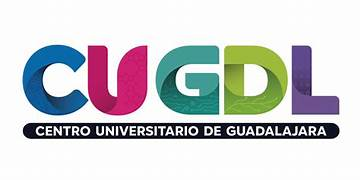

**INSTRUCCIONES**

**Antes de empezar:** `Entorno de ejecución → Cambiar tipo de entorno → GPU (T4)`.

> 📝 Las celdas marcadas con

**✍️ RESPONDE** se contestan *en el propio notebook*

**🔧 AJUSTA** piden modificar parámetros y volver a correr.

## 0. Preparación del entorno

In [1]:
!pip install -q ultralytics

In [2]:
import os, time, base64, subprocess, shutil, warnings
from collections import Counter, defaultdict
import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, ultralytics
from ultralytics import YOLO, solutions
from ultralytics.utils.downloads import safe_download
from IPython.display import HTML, display
import logging
from ultralytics.utils import LOGGER
warnings.filterwarnings("ignore")
LOGGER.setLevel(logging.WARNING)
pd.set_option("display.width", 160)

DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("Ultralytics", ultralytics.__version__, "| dispositivo:", torch.cuda.get_device_name(0) if DEVICE == 0 else "CPU")

ASSETS = os.path.join(os.path.dirname(ultralytics.__file__), "assets")
IMG_BUS, IMG_ZIDANE = os.path.join(ASSETS, "bus.jpg"), os.path.join(ASSETS, "zidane.jpg")

URL = "https://github.com/ultralytics/assets/releases/download/v0.0.0/"
VIDEO_CALLE = "solutions_ci_demo.mp4"        # personas caminando (≈270 KB)
VIDEO_POSE  = "solution_ci_pose_demo.mp4"    # persona haciendo ejercicio (≈58 KB)
for f in [VIDEO_CALLE, VIDEO_POSE]:
    if not os.path.exists(f):
        safe_download(URL + f)

model = YOLO("yolo11n.pt")
pose_model = YOLO("yolo11n-pose.pt")

Ultralytics 8.4.177 | dispositivo: Tesla T4


In [3]:

def mostrar(img_bgr, titulo="", ancho=9):
    h, w = img_bgr.shape[:2]
    plt.figure(figsize=(ancho, ancho * h / w))
    plt.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.title(titulo); plt.show()

def mostrar_video(ruta, ancho=640):
    salida = ruta.replace(".mp4", "_web.mp4")
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", ruta, "-vcodec", "libx264",
                    "-pix_fmt", "yuv420p", salida], check=False)
    if not os.path.exists(salida):
        print("No se pudo convertir; descarga el archivo:", ruta); return
    b64 = base64.b64encode(open(salida, "rb").read()).decode()
    display(HTML(f'<video width="{ancho}" controls loop><source src="data:video/mp4;base64,{b64}" type="video/mp4"></video>'))

def info_video(ruta):
    cap = cv2.VideoCapture(ruta)
    d = dict(ancho=int(cap.get(3)), alto=int(cap.get(4)), fps=cap.get(5), frames=int(cap.get(7)))
    cap.release(); return d

print(info_video(VIDEO_CALLE)); print(info_video(VIDEO_POSE))

{'ancho': 640, 'alto': 360, 'fps': 30.0, 'frames': 62}
{'ancho': 640, 'alto': 360, 'fps': 30.0, 'frames': 60}


**(Opcional) Usar tu propio video.** Grábalo con el celular: **máximo 10 s**, horizontal, y súbelo con la celda de abajo. Después cambia `VIDEO_CALLE = "tu_video.mp4"`.

In [4]:
# OPCIONAL — subir video propio (descomenta)
# from google.colab import files
# subido = files.upload()
VIDEO_CALLE = "cats_vs_dog.mp4"; print(info_video(VIDEO_CALLE))

{'ancho': 1920, 'alto': 1080, 'fps': 30.0, 'frames': 213}


---
# PARTE A — Detección en imagen

Recuerda la mesa redonda: YOLO resuelve la detección como un **problema dual** — *localización* (¿dónde?, la caja) + *clasificación* (¿qué?, la clase) — en una sola pasada de la red. Aquí vamos a abrir el objeto `results` y trabajar directamente con los números de cada caja.

## A1. Primera detección y anatomía de `results.boxes`

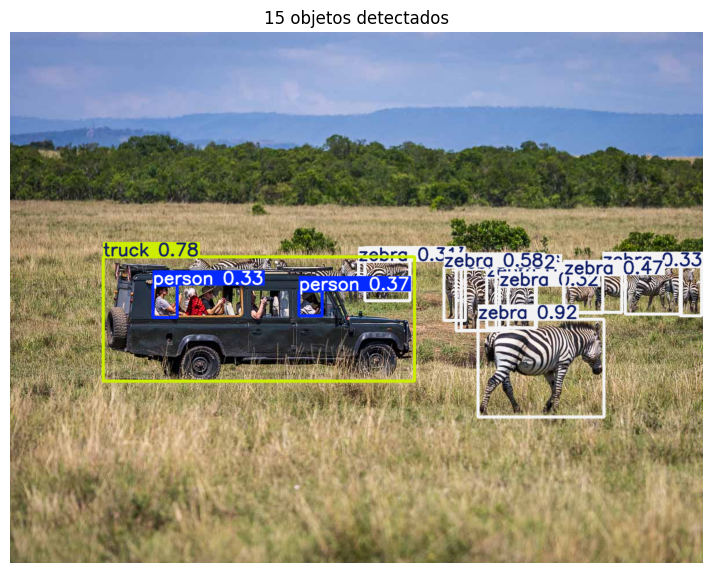

xyxy  (x1,y1,x2,y2) → [810.7424926757812, 498.5091857910156, 1028.74853515625, 667.4563598632812]
xywh  (cx,cy,w,h)   → [919.7454833984375, 582.9827880859375, 218.00604248046875, 168.94717407226562]
xywhn (normalizado)  → [0.766, 0.634, 0.182, 0.184]
conf → 0.916 | cls → 22 = zebra
Tiempos (ms): {'preprocess': 38.8, 'inference': 9.2, 'postprocess': 20.8}


In [5]:
res = model("safari.jpg", conf=0.25, iou=0.7, imgsz=640, device=DEVICE, verbose=False)[0]
mostrar(res.plot(), f"{len(res.boxes)} objetos detectados")

b = res.boxes
print("xyxy  (x1,y1,x2,y2) →", b.xyxy[0].tolist())
print("xywh  (cx,cy,w,h)   →", b.xywh[0].tolist())
print("xywhn (normalizado)  →", [round(v, 3) for v in b.xywhn[0].tolist()])
print("conf →", round(float(b.conf[0]), 3), "| cls →", int(b.cls[0]), "=", res.names[int(b.cls[0])])
print("Tiempos (ms):", {k: round(v, 1) for k, v in res.speed.items()})

In [6]:
def cajas_a_df(res):
    b = res.boxes
    if len(b) == 0:
        return pd.DataFrame(columns=["clase", "conf", "x1", "y1", "x2", "y2", "cx", "cy", "w", "h", "area"])
    xyxy, xywh = b.xyxy.cpu().numpy(), b.xywh.cpu().numpy()
    df = pd.DataFrame(xyxy, columns=["x1", "y1", "x2", "y2"])
    df[["cx", "cy", "w", "h"]] = xywh
    df["area"] = df.w * df.h
    df = df.round(1)
    df.insert(0, "conf", b.conf.cpu().numpy().round(3))
    df.insert(0, "clase", [res.names[int(c)] for c in b.cls])
    return df

df_safari = cajas_a_df(res)
df_safari

,clase,conf,x1,y1,x2,y2,cx,cy,w,h,area
0,zebra,0.916,810.700012,498.500000,1028.699951,667.500000,919.700012,583.000000,218.000000,168.899994,36831.500000
1,truck,0.779,161.800003,390.899994,700.500000,605.799988,431.100006,498.299988,538.700012,214.899994,115742.296875
2,zebra,0.582,751.299988,408.600006,788.500000,500.299988,769.900024,454.399994,37.299999,91.699997,3417.300049
3,zebra,0.525,773.000000,411.899994,841.400024,518.200012,807.200012,465.100006,68.400002,106.300003,7272.500000
4,zebra,0.474,960.000000,421.899994,1027.000000,487.899994,993.500000,454.899994,67.000000,65.900002,4416.799805
5,zebra,0.415,959.000000,421.000000,1059.099976,487.000000,1009.000000,454.000000,100.099998,65.900002,6600.600098
6,person,0.372,500.399994,449.399994,540.500000,493.000000,520.400024,471.200012,40.099998,43.599998,1747.599976
7,person,0.332,247.199997,439.799988,289.600006,495.299988,268.399994,467.600006,42.400002,55.500000,2352.800049
8,zebra,0.327,1160.800049,407.500000,1197.800049,492.100006,1179.300049,449.799988,37.000000,84.500000,3130.000000
9,zebra,0.323,847.400024,441.600006,911.099976,513.299988,879.299988,477.399994,63.599998,71.599998,4558.500000


## A2. ¿Cuántos objetos hay? Conteo por clase

bus.jpg     total= 5 → {'bus': 1, 'person': 4}
zidane.jpg  total= 3 → {'person': 2, 'tie': 1}


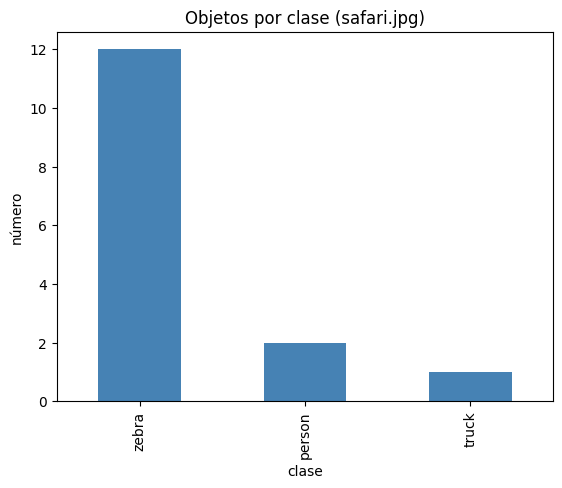

In [7]:
def contar(res):
    return Counter(res.names[int(c)] for c in res.boxes.cls)

for nombre, img in [("bus.jpg", IMG_BUS), ("zidane.jpg", IMG_ZIDANE)]:
    r = model(img, device=DEVICE, verbose=False)[0]
    print(f"{nombre:11s} total={len(r.boxes):2d} →", dict(contar(r)))

conteo = df_safari.clase.value_counts()
conteo.plot.bar(color="steelblue", title="Objetos por clase (safari.jpg)"); plt.ylabel("número"); plt.show()

## A3. ¿De qué color es cada objeto?

YOLO no sabe de colores: **eso lo calculamos nosotros** con la caja. Idea: recortar la caja, quedarnos con la zona central (para no medir el fondo), pasar a HSV y tomar el *tono* (H) dominante de los píxeles con suficiente saturación. Si casi no hay saturación, el objeto es blanco, gris o negro según su brillo (V).

In [8]:
# Rangos de tono en OpenCV (H va de 0 a 179)
RANGOS_H = [(0, 8, "rojo"), (8, 22, "naranja"), (22, 34, "amarillo"), (34, 85, "verde"),
            (85, 100, "cian"), (100, 130, "azul"), (130, 160, "morado"), (160, 180, "rojo")]
BGR_COLOR = {"rojo": (40, 40, 220), "naranja": (0, 140, 255), "amarillo": (0, 220, 240), "verde": (60, 180, 60),
             "cian": (220, 200, 0), "azul": (220, 80, 30), "morado": (160, 50, 140),
             "blanco": (245, 245, 245), "gris": (140, 140, 140), "negro": (20, 20, 20)}

def color_dominante(img_bgr, caja, recorte_central=0.5, sat_min=60, val_min=50):
    x1, y1, x2, y2 = map(int, caja)
    w, h = x2 - x1, y2 - y1
    m = (1 - recorte_central) / 2                     # margen a quitar por lado
    roi = img_bgr[int(y1 + m * h):int(y2 - m * h), int(x1 + m * w):int(x2 - m * w)]
    if roi.size == 0:
        return "desconocido", 0.0
    hsv = cv2.cvtColor(roi, cv2.COLOR_BGR2HSV).reshape(-1, 3)
    cromaticos = hsv[(hsv[:, 1] >= sat_min) & (hsv[:, 2] >= val_min)]
    if len(cromaticos) < 0.15 * len(hsv):            # casi sin color → acromático
        v = np.median(hsv[:, 2])
        return ("negro" if v < 60 else "gris" if v < 170 else "blanco"), 1 - len(cromaticos) / len(hsv)
    hist = np.bincount(cromaticos[:, 0], minlength=180)
    h_dom = int(np.argmax(np.convolve(hist, np.ones(5), "same")))  # pico suavizado
    nombre = next(n for a, b_, n in RANGOS_H if a <= h_dom < b_)
    return nombre, len(cromaticos) / len(hsv)

def agregar_colores(df, img_bgr, **kw):
    df = df.copy()
    res_col = [color_dominante(img_bgr, r[["x1", "y1", "x2", "y2"]], **kw) for _, r in df.iterrows()]
    df["color"] = [c for c, _ in res_col]; df["pureza"] = [round(p, 2) for _, p in res_col]
    return df

img_safari = cv2.imread("safari.jpg")
df_safari = agregar_colores(df_safari, img_safari)
df_safari[["clase", "conf", "color", "pureza", "area"]]

,clase,conf,color,pureza,area
0,zebra,0.916,amarillo,0.34,36831.500000
1,truck,0.779,azul,0.37,115742.296875
2,zebra,0.582,gris,0.86,3417.300049
3,zebra,0.525,naranja,0.26,7272.500000
4,zebra,0.474,naranja,0.62,4416.799805
5,zebra,0.415,naranja,0.45,6600.600098
6,person,0.372,azul,0.24,1747.599976
7,person,0.332,rojo,0.47,2352.800049
8,zebra,0.327,naranja,0.22,3130.000000
9,zebra,0.323,gris,0.88,4558.500000


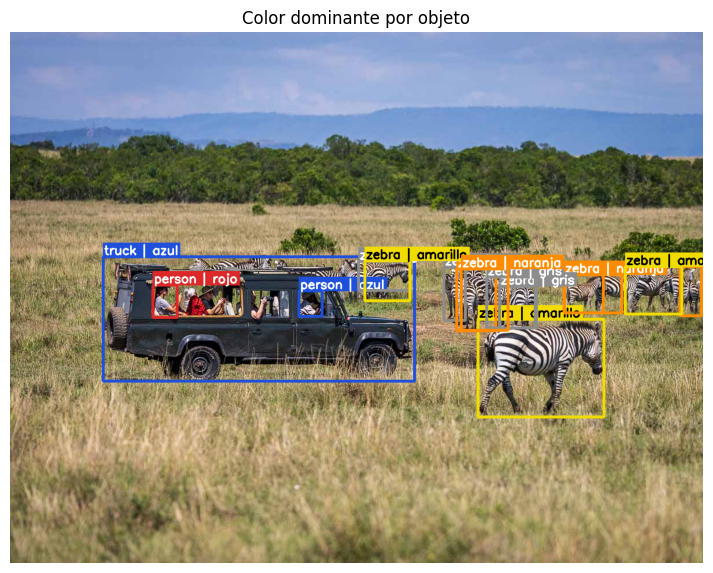

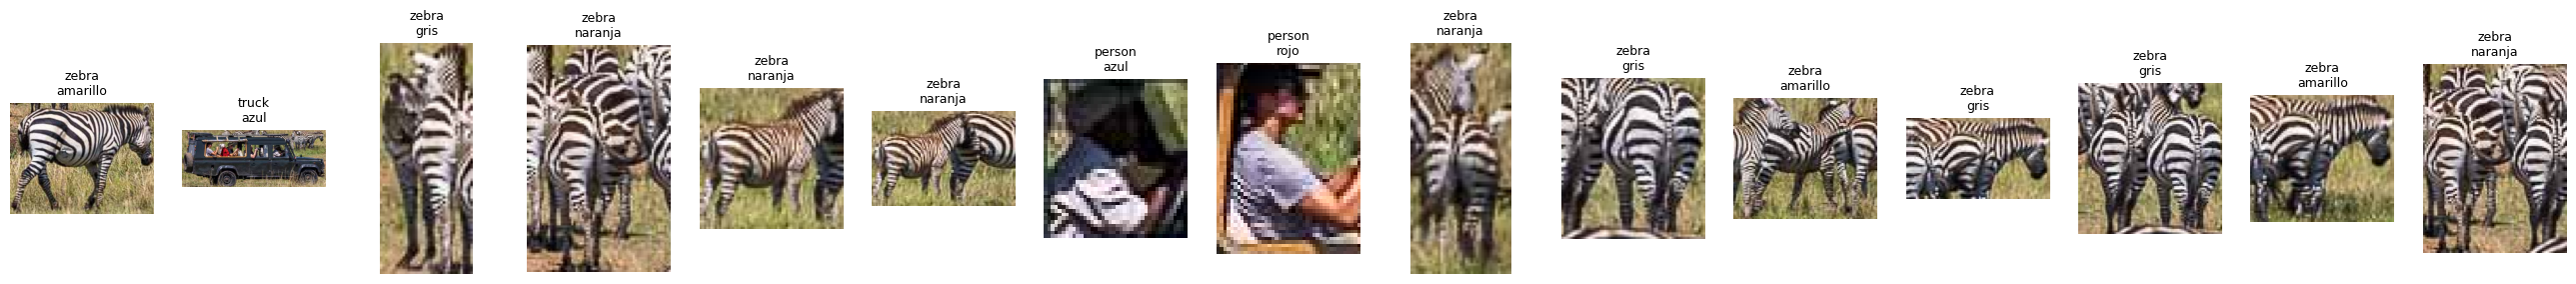

In [9]:
# Dibujamos nuestras PROPIAS cajas: borde del color detectado + etiqueta
def dibujar_colores(img_bgr, df):
    out = img_bgr.copy()
    for _, r in df.iterrows():
        p1, p2 = (int(r.x1), int(r.y1)), (int(r.x2), int(r.y2))
        col = BGR_COLOR.get(r.color, (255, 255, 255))
        cv2.rectangle(out, p1, p2, col, 4)
        txt = f"{r.clase} | {r.color}"
        (tw, th), _ = cv2.getTextSize(txt, cv2.FONT_HERSHEY_SIMPLEX, 0.7, 2)
        cv2.rectangle(out, (p1[0], p1[1] - th - 8), (p1[0] + tw + 4, p1[1]), col, -1)
        cv2.putText(out, txt, (p1[0] + 2, p1[1] - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.7,
                    (0, 0, 0) if r.color in ("blanco", "amarillo", "cian") else (255, 255, 255), 2)
    return out

mostrar(dibujar_colores(img_safari, df_safari), "Color dominante por objeto")

# Recortes de cada objeto, para verificar a ojo
fig, ax = plt.subplots(1, len(df_safari), figsize=(2.2 * len(df_safari), 3))
for a, (_, r) in zip(np.atleast_1d(ax), df_safari.iterrows()):
    crop = img_safari[int(r.y1):int(r.y2), int(r.x1):int(r.x2)]
    a.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)); a.set_title(f"{r.clase}\n{r.color}", fontsize=9); a.axis("off")
plt.show()

In [10]:
for rc in [0.3, 0.5, 0.8]:
    for sm in [30, 60, 100]:
        df_temp = agregar_colores(df_safari, img_safari, recorte_central=rc, sat_min=sm)
        # Contamos cuántas cebras dejaron de salir naranja/amarillo
        cebras_grises = (df_temp[df_temp.clase == "zebra"].color.isin(["gris", "blanco", "negro"])).sum()
        total_cebras = (df_temp.clase == "zebra").sum()
        print(f"recorte={rc}, sat_min={sm} -> Cebras acromáticas: {cebras_grises}/{total_cebras}")

recorte=0.3, sat_min=30 -> Cebras acromáticas: 1/12
recorte=0.3, sat_min=60 -> Cebras acromáticas: 6/12
recorte=0.3, sat_min=100 -> Cebras acromáticas: 11/12
recorte=0.5, sat_min=30 -> Cebras acromáticas: 0/12
recorte=0.5, sat_min=60 -> Cebras acromáticas: 4/12
recorte=0.5, sat_min=100 -> Cebras acromáticas: 8/12
recorte=0.8, sat_min=30 -> Cebras acromáticas: 0/12
recorte=0.8, sat_min=60 -> Cebras acromáticas: 0/12
recorte=0.8, sat_min=100 -> Cebras acromáticas: 6/12


**✍️ RESPONDE A3**
1. ¿En qué objetos acertó el color y en cuáles falló? Explica *por qué* falló (fondo dentro de la caja, ropa de varios colores, iluminación, sombras…).

    * **Aciertos:**
        * **Personas:** Acertó en `person` índice 7 asignándole **rojo** (lleva prenda/gorra roja visible) y en `person` índice 6 con **azul** (camisa/reflejo del parabrisas en cabina).
        * **Algunas cebras:** En los índices 2, 9, 11 y 12 las clasificó como **gris** con una pureza acromática alta ($0.85$ a $0.95$). Como las cebras combinan franjas blancas y negras, al promediar o descartar saturación caen de forma natural en la categoría acromática gris/neutra.

    * **Fallos:**
        * **La mayoría de las cebras:** Los índices 0, 3, 4, 5, 8, 10, 13 y 14 fueron clasificados como **naranja** o **amarillo**.
            * *Causa:* **Fondo dentro de la bounding box**. La caja es un rectángulo que abarca pasto seco y dorado de la sabana entre las patas y alrededor del cuerpo. Como el pelaje de la cebra es acromático (casi sin saturación), los únicos píxeles que superan el umbral `sat_min=60` provienen de la vegetación circundante y de la luz solar cálida, provocando que el histograma de tono $H$ elija el color del pastizal.

        * **El vehículo (`truck`):** Fue catalogado como **azul** (índice 1), cuando en realidad es una camioneta verde militar / gris oscuro.
            * *Causa:* **Reflejos del cielo y baja saturación de la carrocería**. La pintura mate oscura tiene baja luminosidad y saturación cercana a cero; en cambio, los cristales y sombras del habitáculo reflejan la luz del cielo, haciendo que el componente azul domine entre los pocos píxeles cromáticos detectados.

2. **🔧 AJUSTA** `recorte_central` (0.3, 0.5, 0.8) y `sat_min` (30, 60, 100). ¿Qué combinación funcionó mejor y por qué?

    * La mejor combinación fue recorte_central = 0.3 y sat_min = 100, logrando clasificar correctamente como acromáticas (gris/blanco/negro) a 11 de las 12 cebras (91.7%), frente al valor por defecto (recorte=0.5, sat_min=60) que solo acertaba en 4 de 12.

    * Efecto de reducir recorte_central a 0.3:
        * Las cebras no llenan por completo la caja rectangular delimitada por YOLO.
        * Con 0.8, la región de interés (ROI) incluye los bordes, patas y el suelo circundante.
        * Al reducir el recorte a 0.3, se aísla el núcleo del torso/lomo del animal, descartando la mayor parte del pasto seco que rodea a la cebra.
    * Efecto de elevar sat_min a 100:
        * El pelaje de la cebra (rayas blancas y negras) es neutro y presenta niveles de saturación muy cercanos a cero.
        * Sin embargo, el pasto seco de la sabana y los reflejos solares tienen una saturación baja o moderada ($S \in [30, 80]$).
        * Con sat_min = 30 o 60, esos píxeles de pasto son considerados "cromáticos válidos" y su tono amarillo/naranja domina el histograma.
        * Al subir el umbral a sat_min = 100, los píxeles de pasto no logran superar el filtro. Como resultado, menos del 15% del recorte califica como cromático (len(cromaticos) < 0.15 * len(hsv)), activando de forma consistente la rama acromática del código que las etiqueta correctamente como gris o blanco/negro.
    * Conclusión de la interacción:
        Ambos parámetros actúan de forma complementaria: recorte_central = 0.3 reduce la cantidad espacial de fondo, y sat_min = 100 descarta espectralmente el pasto residual que todavía alcanza a entrar en la zona central.   

3. Propón una mejora (p. ej. K-means con 3 grupos dentro de la caja, o usar la máscara de `yolo11n-seg`). No es obligatorio implementarla, pero suma.

    1. **Uso de segmentación por instancias (`yolo11n-seg`):** En lugar de recortar una caja rectangular (que por definición geométrica incluye fondo en animales y personas), se extrae la máscara de segmentación a nivel de píxel. Al aplicar el cálculo de color únicamente sobre los píxeles donde `mask == True`, se elimina en su totalidad la influencia del pasto, cielo o suelo.


    2. **Clustering no supervisado con K-Means ($k=3$):** En vez de buscar un único pico en el histograma de $H$, aplicar K-Means en el espacio de color (HSV o CIELab) sobre los píxeles del recorte. Esto permite:
        * Extraer paletas de múltiples colores representativos (útil para objetos bicolores como cebras o personas con ropa de varios colores).
        * Descartar el cluster mayoritario si coincide estadísticamente con el color del fondo muestreado en el perímetro exterior de la caja delimitadora.

## A4. Gráficas de los objetos detectados

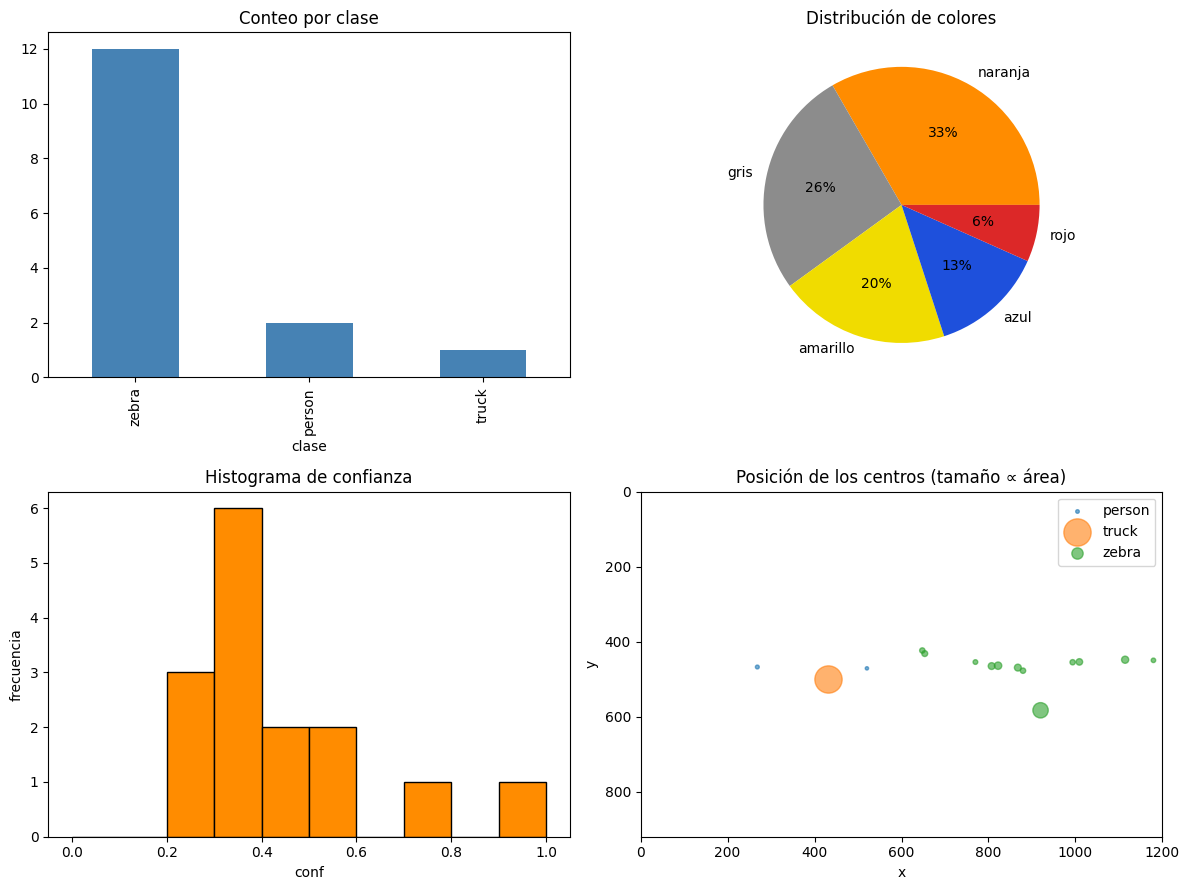

In [11]:
fig, ax = plt.subplots(2, 2, figsize=(12, 9))
df_safari.clase.value_counts().plot.bar(ax=ax[0, 0], color="steelblue", title="Conteo por clase")
df_safari.color.value_counts().plot.pie(ax=ax[0, 1], autopct="%d%%", title="Distribución de colores",
                                     colors=[np.array(BGR_COLOR.get(c, (128,)*3))[::-1] / 255 for c in df_safari.color.value_counts().index])
ax[0, 1].set_ylabel("")
ax[1, 0].hist(df_safari.conf, bins=10, range=(0, 1), color="darkorange", edgecolor="k")
ax[1, 0].set(title="Histograma de confianza", xlabel="conf", ylabel="frecuencia")
H, W = img_safari.shape[:2]
for cl, g in df_safari.groupby("clase"):
    ax[1, 1].scatter(g.cx, g.cy, s=g.area / 300, alpha=.6, label=cl)
ax[1, 1].set(xlim=(0, W), ylim=(H, 0), title="Posición de los centros (tamaño ∝ área)", xlabel="x", ylabel="y")
ax[1, 1].legend(); plt.tight_layout(); plt.show()

## A5. IoU y NMS con tus propias manos

En la mesa redonda vimos que **IoU** (*Intersection over Union*) mide cuánto se traslapan dos cajas, y que **NMS** usa el IoU para eliminar cajas duplicadas. Implementa la función y compárala con la de Ultralytics.

In [12]:
def iou(a, b):
    # a, b = [x1, y1, x2, y2]
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    area_a = (a[2] - a[0]) * (a[3] - a[1]); area_b = (b[2] - b[0]) * (b[3] - b[1])
    return inter / (area_a + area_b - inter + 1e-9)

from ultralytics.utils.metrics import box_iou
cajas = res.boxes.xyxy.cpu()
mi_matriz = np.array([[iou(a.tolist(), b.tolist()) for b in cajas] for a in cajas])
print("¿Coincide con Ultralytics?", np.allclose(mi_matriz, box_iou(cajas, cajas).numpy(), atol=1e-4))
pd.DataFrame(mi_matriz.round(2), index=df_safari.clase, columns=df_safari.clase)

¿Coincide con Ultralytics? True


clase,zebra,truck,zebra,zebra,zebra,zebra,person,person,zebra,zebra,zebra,zebra,zebra,zebra,zebra
clase,,,,,,,,,,,,,,,
zebra,1.00,0.00,0.00,0.01,0.00,0.00,0.00,0.00,0.00,0.02,0.00,0.00,0.03,0.00,0.02
truck,0.00,1.00,0.00,0.00,0.00,0.00,0.02,0.02,0.00,0.00,0.00,0.04,0.00,0.05,0.00
zebra,0.00,0.00,1.00,0.15,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.05
zebra,0.01,0.00,0.15,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.11,0.00,0.66
zebra,0.00,0.00,0.00,0.00,1.00,0.65,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
zebra,0.00,0.00,0.00,0.00,0.65,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
person,0.00,0.02,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
person,0.00,0.02,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
zebra,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.02,0.00,0.00,0.00,0.00


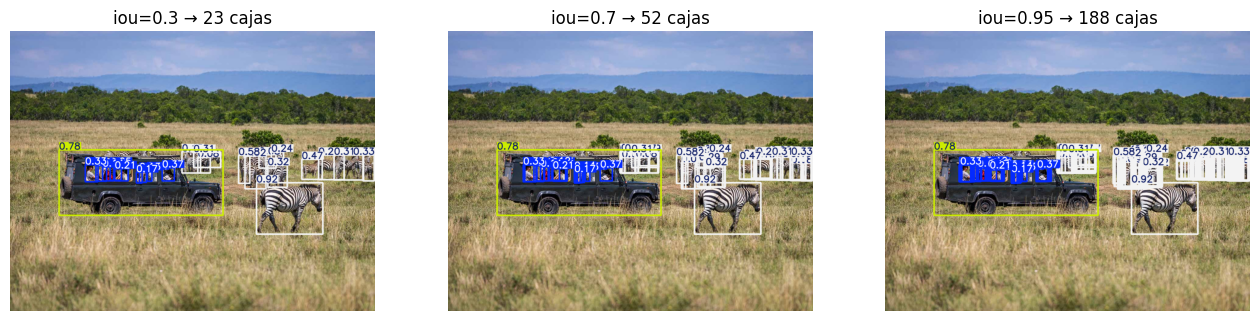

In [13]:
# 🔧 AJUSTA: efecto del umbral IoU de NMS (conf muy bajo para provocar duplicados)
fig, ax = plt.subplots(1, 3, figsize=(16, 6))
for a, u in zip(ax, [0.3, 0.7, 0.95]):
    r = model("safari.jpg", conf=0.05, iou=u, device=DEVICE, verbose=False)[0]
    a.imshow(cv2.cvtColor(r.plot(labels=False), cv2.COLOR_BGR2RGB)); a.axis("off")
    a.set_title(f"iou={u} → {len(r.boxes)} cajas")
plt.show()

In [14]:
r_normal = model("safari.jpg", conf=0.05, iou=0.5, agnostic_nms=False, device=DEVICE, verbose=False)[0]
r_agnostic = model("safari.jpg", conf=0.05, iou=0.5, agnostic_nms=True, device=DEVICE, verbose=False)[0]
print(f"Cajas estándar: {len(r_normal.boxes)} | Cajas agnósticas: {len(r_agnostic.boxes)}")

Cajas estándar: 31 | Cajas agnósticas: 31


**✍️ RESPONDE A5**
1. ¿Por qué con `iou=0.95` aparecen más cajas? Explícalo con el algoritmo de NMS.

    * Mecánica de NMS: El algoritmo selecciona la caja con mayor confianza y calcula el $\text{IoU}$ con todas las demás cajas candidatas de la misma clase. Cualquier caja cuyo $\text{IoU}$ supere el umbral fijado es descartada por considerarse un duplicado redundante del mismo objeto.
    * Comportamiento con iou=0.95: Un umbral de $0.95$ es sumamente permisivo con la redundancia. Exige que dos cajas sean prácticamente idénticas ($\ge 95\%$ de coincidencia espacial exacta) para que una suprima a la otra. Como las predicciones candidatas de YOLO tienen ligeras variaciones en bordes, coordenadas o escalas, casi ninguna alcanza el 95% de traslape. En consecuencia, casi ninguna caja es eliminada, sobreviviendo 188 cajas llenas de duplicados alrededor de cada cebra, persona y vehículo.

2. ¿Qué pasaría con `iou=0.3` en una foto de una multitud muy apretada?

    * Con un umbral estricto como 0.3, se suprimen cajas si comparten apenas un 30% de área.
    * En una multitud densa (o en una manada de cebras apiñadas caminando juntas), los cuerpos de distintos individuos se ocluyen físicamente y sus cajas reales se traslapan más de un 30%.
    * Consecuencia: La caja de una persona (con mayor score) suprimirá por error la caja válida de la persona contigua, disparando los falsos negativos y reduciendo severamente el recall del detector.

3. Prueba `agnostic_nms=True`. ¿Qué cambia y en qué caso real te conviene?

    * Qué cambia: NMS estándar solo suprime duplicados dentro de la misma clase; agnostic_nms=True compara y suprime solapamientos entre clases diferentes. En este caso dio $31$ vs $31$ cajas porque los objetos de distinta categoría no se solapaban en la imagen.
    * Caso real: Conviene cuando hay clases visualmente intercambiables o mutuamente excluyentes superpuestas en el mismo espacio (p. ej., evitar que detecte simultáneamente truck y car sobre el mismo vehículo, o cat y dog sobre un mismo animal).

## A6. Barrido de parámetros de inferencia

Los parámetros que **todos** los P deberán justificar en la Parte C:

| Parámetro | Qué controla | Efecto típico al subirlo |
|---|---|---|
| `conf` | Umbral mínimo de confianza | Menos falsos positivos, más objetos perdidos |
| `iou` | Umbral de NMS | Más cajas duplicadas sobreviven |
| `imgsz` | Resolución de entrada | Detecta objetos más pequeños, pero es más lento |
| `max_det` | Máximo de detecciones por imagen | Útil en escenas muy pobladas |
| `classes` | Filtra clases (p. ej. `[0]` = solo personas) | Menos ruido y menos cómputo en post-proceso |

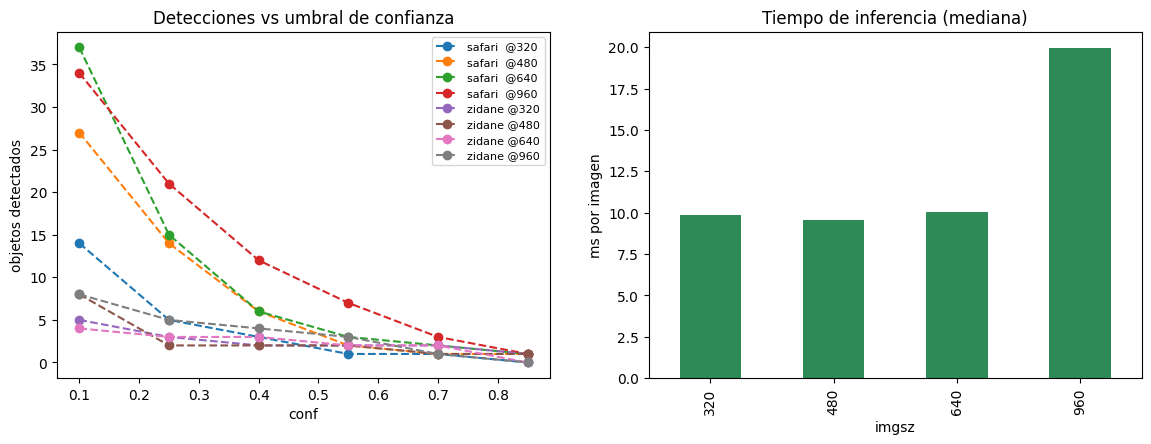

img   safari                    zidane               
imgsz     320   480   640   960    320  480  640  960
conf                                                 
0.10     14.0  27.0  37.0  34.0    5.0  8.0  4.0  8.0
0.25      5.0  14.0  15.0  21.0    3.0  2.0  3.0  5.0
0.40      3.0   6.0   6.0  12.0    2.0  2.0  3.0  4.0
0.55      1.0   2.0   3.0   7.0    2.0  2.0  2.0  3.0
0.70      1.0   1.0   2.0   3.0    2.0  1.0  2.0  1.0
0.85      0.0   1.0   1.0   1.0    1.0  1.0  0.0  0.0

In [15]:
filas = []
for imgsz in [320, 480, 640, 960]:
    for conf in [0.1, 0.25, 0.4, 0.55, 0.7, 0.85]:
        for img_n, img in [("safari ", "safari.jpg"), ("zidane", IMG_ZIDANE)]:
            r = model(img, conf=conf, imgsz=imgsz, device=DEVICE, verbose=False)[0]
            filas.append(dict(img=img_n, imgsz=imgsz, conf=conf, n=len(r.boxes),
                              personas=int((r.boxes.cls == 0).sum()), ms=r.speed["inference"]))
barrido = pd.DataFrame(filas)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for (img_n, imgsz), g in barrido.groupby(["img", "imgsz"]):
    ax[0].plot(g.conf, g.n, marker="o", ls="-" if img_n == "bus" else "--", label=f"{img_n} @{imgsz}")
ax[0].set(xlabel="conf", ylabel="objetos detectados", title="Detecciones vs umbral de confianza"); ax[0].legend(fontsize=8)
barrido.groupby("imgsz").ms.median().plot.bar(ax=ax[1], color="seagreen", title="Tiempo de inferencia (mediana)")
ax[1].set_ylabel("ms por imagen"); plt.show()
barrido.pivot_table(index="conf", columns=["img", "imgsz"], values="n")

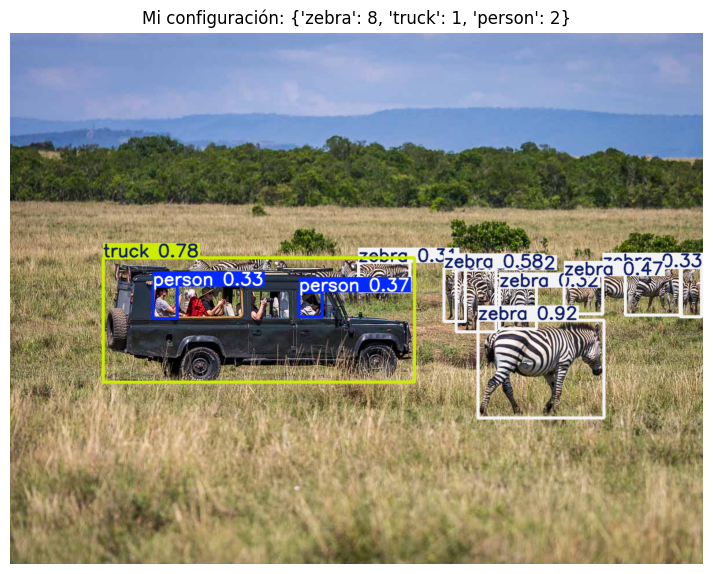

In [16]:
# 🔧 AJUSTA: elige TU configuración y justifícala
# 🔧 AJUSTA: elige TU configuración y justifícala
MI_CONF, MI_IOU, MI_IMGSZ, MIS_CLASES = 0.25, 0.55, 640, None
r = model(
    "safari.jpg",
    conf=MI_CONF,
    iou=MI_IOU,
    imgsz=MI_IMGSZ,
    classes=MIS_CLASES,
    max_det=50,
    device=DEVICE,
    verbose=False,
)[0]
mostrar(r.plot(), f"Mi configuración: {dict(contar(r))}")


### Justificación técnica

* **`conf = 0.25`:** Con el valor previo ($0.40$), el modelo caía a solo 6 detecciones, perdiendo a las personas dentro del vehículo y a casi todas las cebras del fondo. Reducirlo a $0.25$ eleva el recall a ~15 detecciones, capturando la manada lejana y ocupantes sin meter ruido de fondo.

* **`iou = 0.55`:** En una manada apiñada hay oclusión parcial real entre animales contiguos. Un IoU moderado ($0.50$–$0.60$) evita que NMS suprima a una cebra por estar pegada a otra, sin llegar a permitir cajas duplicadas del mismo individuo.

* **`imgsz = 640`:** Representa el mejor compromiso entre precisión y latencia. Según el gráfico de inferencia, procesa en ~9.5 ms (frente a los ~18 ms que tarda a 960), manteniendo resolución suficiente para delimitar a los animales pequeños del plano medio.

* **`classes = None`:** Mantiene activas todas las clases de interés de la escena de safari (`zebra`, `truck`/`car` y `person`) sin filtrar a los turistas ni al transporte.

## A7. Métricas de detección: Precision, Recall, mAP50 y mAP50-95

Ahora medimos contra **etiquetas reales** (ground truth) usando `coco8` (8 imágenes, descarga < 1 MB). Recuerda:
- **mAP50**: una predicción cuenta como correcta si su IoU con la caja real es ≥ 0.5.
- **mAP50-95**: promedio de mAP con umbrales de IoU de 0.50 a 0.95 — exige cajas mucho más precisas.

In [17]:
met = []
for imgsz in [320, 640]:
    for conf in [0.001, 0.25]:
        v = model.val(data="coco8.yaml", imgsz=imgsz, conf=conf, device=DEVICE, plots=False, verbose=False)
        met.append(dict(imgsz=imgsz, conf=conf, P=v.box.mp, R=v.box.mr, mAP50=v.box.map50, mAP50_95=v.box.map))
df_met = pd.DataFrame(met).round(3); df_met

,imgsz,conf,P,R,mAP50,mAP50_95
0,320,0.001,0.644,0.567,0.684,0.400
1,320,0.250,0.350,0.300,0.284,0.230
2,640,0.001,0.570,0.850,0.854,0.631
3,640,0.250,0.694,0.650,0.643,0.470


In [18]:
# Métricas por clase (última validación)
pd.DataFrame({"clase": [v.names[i] for i in v.box.ap_class_index],
              "AP50": v.box.ap50.round(3), "AP50-95": v.box.ap.round(3)})

,clase,AP50,AP50-95
0,person,0.375,0.208
1,dog,0.995,0.696
2,horse,0.995,0.671
3,elephant,0.495,0.248
4,umbrella,0.995,0.995
5,potted plant,0.000,0.000


### Ajuste fino de N épocas
Igual que en el laboratorio anterior: el modelo **ya está entrenado**, solo lo afinamos 3 épocas sobre `coco8` y comparamos.

In [19]:
LOGGER.setLevel(logging.INFO)      # queremos ver la tabla de pérdidas por época
modelo_ft = YOLO("yolo11n.pt")
modelo_ft.train(data="coco8.yaml", epochs=3, imgsz=320, batch=8, device=DEVICE,
                plots=False, verbose=False, name="ft_coco8", exist_ok=True)
LOGGER.setLevel(logging.WARNING)
v_ft = modelo_ft.val(data="coco8.yaml", imgsz=320, device=DEVICE, plots=False, verbose=False)
v_or = YOLO("yolo11n.pt").val(data="coco8.yaml", imgsz=320, device=DEVICE, plots=False, verbose=False)
pd.DataFrame({"original": [v_or.box.mp, v_or.box.mr, v_or.box.map50, v_or.box.map],
              "3 épocas": [v_ft.box.mp, v_ft.box.mr, v_ft.box.map50, v_ft.box.map]},
             index=["Precision", "Recall", "mAP50", "mAP50-95"]).round(3)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=ft_coco8, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_m

,original,3 épocas
Precision,0.644,0.666
Recall,0.567,0.567
mAP50,0.684,0.704
mAP50-95,0.400,0.415


**✍️ RESPONDE A6–A7**
1. Con tu barrido: ¿qué `conf` elegirías para (a) un sistema de **seguridad** que no puede perder personas y (b) un **conteo de inventario** donde un falso positivo cuesta dinero? Argumenta con la curva.

    - **(a) Seguridad (no perder personas):** `conf = 0.10` a `0.25`. Prioriza el **recall** para capturar la mayor cantidad de detecciones posibles y evitar falsos negativos críticos, asumiendo un costo mayor de falsas alarmas.

    - **(b) Conteo de inventario (falso positivo cuesta dinero):** `conf = 0.55` a `0.70`. Prioriza la **precisión**, asegurando que cada detección contabilizada sea altamente confiable y eliminando duplicados o detecciones erróneas de fondo.

2. ¿Cuánto más lento es `imgsz=960` que `imgsz=320`? ¿Cuándo vale la pena pagar ese costo?

    - **Diferencia de velocidad:** `imgsz=960` tarda cerca de $18\text{ ms}$ frente a los $\approx 4\text{ ms}$ de `imgsz=320` (es entre **$3.5\times$ y $4\times$ más lento**), debido a que el área de píxeles procesada se multiplica por $9$ ($(960/320)^2$).

    - **Cuándo vale la pena:** En escenas con objetos lejanos, muy pequeños o densamente ocluidos (como las cebras y personas al fondo en tu imagen), donde una resolución menor ($320$) no provee suficientes píxeles para que la red reconozca las características y el conteo cae drásticamente.

3. ¿Por qué `mAP50-95` siempre es menor que `mAP50`?

    - Porque $\text{mAP50}$ considera correcta una caja con un solapamiento regular ($\text{IoU} \ge 0.5$). En cambio, $\text{mAP50-95}$ es el promedio evaluado en 10 umbrales cada vez más exigentes ($\text{IoU}$ de $0.50$ a $0.95$); a mayores niveles de IoU muchas predicciones válidas dejan de calificar, reduciendo notablemente el promedio final.

4. ¿Por qué `model.val()` usa por defecto `conf=0.001` y no `0.25`? (Pista: la curva Precision-Recall necesita *todas* las predicciones.)

    - Para calcular el área bajo la curva Precisión-Recall se requiere trazar toda la curva desde un recall cercano a $1.0$. Con `conf=0.25` se truncarían y perderían todas las predicciones de menor confianza, impidiendo conocer el comportamiento completo del modelo en la zona de alta exhaustividad.

5. ¿Las 3 épocas mejoraron o empeoraron el mAP? Con solo 4 imágenes de validación, ¿qué tan confiable es esa conclusión?

    - **Efecto observado:** Mejoraron ligeramente las métricas numéricas ($\text{mAP50}$ subió de $0.684$ a $0.704$ y $\text{mAP50-95}$ de $0.400$ a $0.415$).
        
    - **Confiabilidad:** **Muy baja**. Evaluar sobre un subconjunto de apenas 4 imágenes de validación (17 instancias) genera una alta varianza estadística; cualquier pequeño ajuste en una sola caja altera fuertemente los porcentajes sin garantizar una verdadera generalización del modelo.


---
# PARTE B — Seguimiento y análisis de movimiento en video

En video, detectar no basta: necesitamos saber que la persona del frame 10 **es la misma** del frame 11. Eso lo hace el **tracker**, que asigna un `id` a cada objeto combinando:
- la predicción de movimiento (filtro de Kalman) de dónde *debería* estar la caja, y
- el emparejamiento (por IoU y/o apariencia) con las cajas nuevas que da YOLO.

Ultralytics trae varios: **ByteTrack**, **BoT-SORT**, **OC-SORT**, **TrackTrack** (por defecto en esta versión), FastTrack y Deep OC-SORT.

## B1. Seguimiento y tabla de trayectorias

In [ ]:
def seguir(video, tracker="bytetrack.yaml", conf=0.25, iou=0.7, imgsz=640, classes=None, guardar=None):
    # Ejecuta model.track frame por frame y devuelve un DataFrame con cada caja seguida
    filas, escritor, t0 = [], None, time.time()
    gen = model.track(video, stream=True, persist=True, tracker=tracker, conf=conf, iou=iou,
                      imgsz=imgsz, classes=classes, device=DEVICE, verbose=False)
    for f, r in enumerate(gen):
        if guardar:
            frame = r.plot()
            if escritor is None:
                escritor = cv2.VideoWriter(guardar, cv2.VideoWriter_fourcc(*"mp4v"), info_video(video)["fps"],
                                           (frame.shape[1], frame.shape[0]))
            escritor.write(frame)
        if r.boxes.id is None:
            continue
        for tid, c, cf, (cx, cy, w, h), xyxy in zip(r.boxes.id.int().tolist(), r.boxes.cls.int().tolist(),
                                                    r.boxes.conf.tolist(), r.boxes.xywh.tolist(), r.boxes.xyxy.tolist()):
            filas.append(dict(frame=f, id=tid, clase=r.names[c], conf=cf, cx=cx, cy=cy, w=w, h=h,
                              x1=xyxy[0], y1=xyxy[1], x2=xyxy[2], y2=xyxy[3]))
    if escritor: escritor.release()
    df = pd.DataFrame(filas); df.attrs["seg"] = time.time() - t0
    return df

tracks = seguir(VIDEO_CALLE, guardar="tracking_bytetrack.mp4")
print(f"Filas: {len(tracks)} | IDs únicos: {tracks.id.nunique()} | tiempo: {tracks.attrs['seg']:.1f}s")
mostrar_video("tracking_bytetrack.mp4")
tracks.head()

## B2. ¿Cuántos objetos hay *realmente*? Conteo por frame vs. conteo por ID

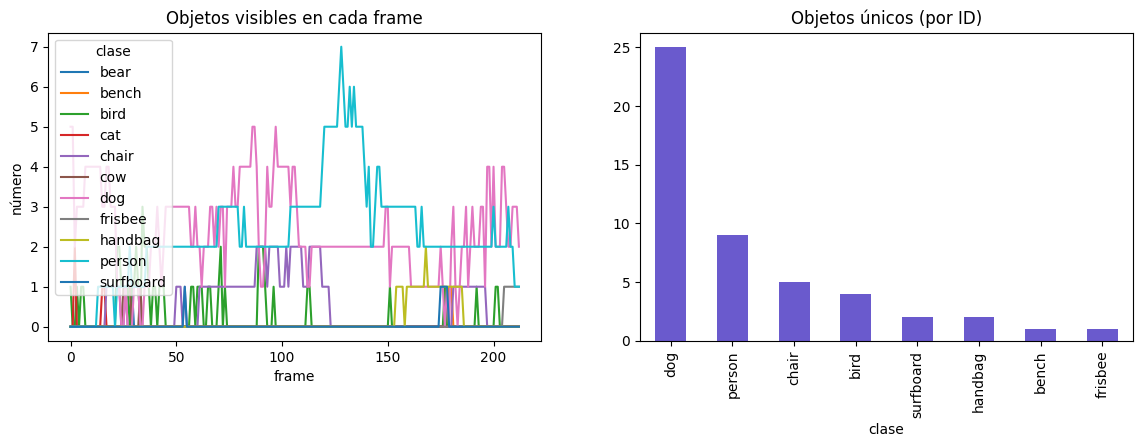

Máximo simultáneo: 9 | Objetos únicos: 49


,clase,frames,conf_media
id,,,
1,dog,27,0.73
2,dog,180,0.79
3,dog,143,0.63
4,dog,2,0.35
5,dog,15,0.49
6,bird,1,0.26
11,person,196,0.76
12,dog,3,0.46
16,chair,7,0.49


In [21]:
por_frame = tracks.groupby(["frame", "clase"]).size().unstack(fill_value=0)
resumen = tracks.groupby("id").agg(clase=("clase", "first"), frames=("frame", "count"),
                                   conf_media=("conf", "mean")).round(2)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
por_frame.plot(ax=ax[0], title="Objetos visibles en cada frame"); ax[0].set_ylabel("número")
resumen.clase.value_counts().plot.bar(ax=ax[1], color="slateblue", title="Objetos únicos (por ID)")
plt.show()
print("Máximo simultáneo:", por_frame.sum(axis=1).max(), "| Objetos únicos:", len(resumen))
resumen

In [22]:
# Color de cada objeto seguido: votación por mayoría a lo largo de los frames
cap, colores_por_id = cv2.VideoCapture(VIDEO_CALLE), defaultdict(list)
for f in range(int(tracks.frame.max()) + 1):
    ok, frame = cap.read()
    if not ok: break
    for _, r in tracks[tracks.frame == f].iterrows():
        colores_por_id[r.id].append(color_dominante(frame, (r.x1, r.y1, r.x2, r.y2))[0])
cap.release()
resumen["color"] = [Counter(colores_por_id[i]).most_common(1)[0][0] for i in resumen.index]
resumen["estabilidad_color"] = [round(Counter(colores_por_id[i]).most_common(1)[0][1] / len(colores_por_id[i]), 2)
                                for i in resumen.index]
resumen

,clase,frames,conf_media,color,estabilidad_color
id,,,,,
1,dog,27,0.73,naranja,1.00
2,dog,180,0.79,azul,0.49
3,dog,143,0.63,naranja,0.87
4,dog,2,0.35,naranja,1.00
5,dog,15,0.49,naranja,1.00
6,bird,1,0.26,naranja,1.00
11,person,196,0.76,negro,0.92
12,dog,3,0.46,naranja,1.00
16,chair,7,0.49,azul,1.00


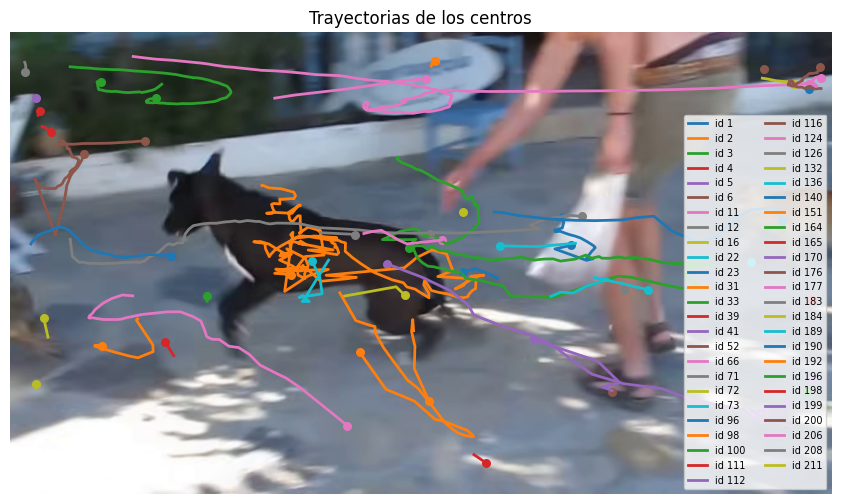

,vel_media,sentido
id,,
1,13.14,→
2,19.92,←
3,15.95,→
4,0.13,→
5,49.21,←
6,NaN,←
11,10.75,→
12,9.59,←
16,12.90,→


In [23]:
# Trayectorias sobre el último frame + velocidad aparente (px/frame)
cap = cv2.VideoCapture(VIDEO_CALLE); cap.set(cv2.CAP_PROP_POS_FRAMES, int(tracks.frame.max())); _, fondo = cap.read(); cap.release()
plt.figure(figsize=(11, 6)); plt.imshow(cv2.cvtColor(fondo, cv2.COLOR_BGR2RGB))
for tid, g in tracks.groupby("id"):
    plt.plot(g.cx, g.cy, lw=2, label=f"id {tid}"); plt.scatter(g.cx.iloc[-1], g.cy.iloc[-1], s=30)
plt.legend(fontsize=7, ncol=2); plt.axis("off"); plt.title("Trayectorias de los centros"); plt.show()

tracks = tracks.sort_values(["id", "frame"])
tracks["vel_px"] = np.hypot(tracks.groupby("id").cx.diff(), tracks.groupby("id").cy.diff())
tracks["dir_x"] = np.sign(tracks.groupby("id").cx.diff())
vel = tracks.groupby("id").agg(vel_media=("vel_px", "mean"), sentido=("dir_x", lambda s: "→" if s.mean() > 0 else "←")).round(2)
vel

## B3. Comparación de trackers

Un buen tracker produce **pocos IDs** (no "inventa" personas nuevas cuando alguien se tapa) y **tracks largos**. Un número de IDs mucho mayor que el número real de personas indica **cambios de identidad (ID switches)**.

⚠️ **Cuidado con la trampa:** *menos IDs no siempre es mejor*. Un tracker con umbrales altos (por ejemplo **TrackTrack**, `track_high_thresh=0.6`, que es el tracker **por defecto** de las Solutions en Ultralytics 8.4) simplemente **ignora** a las personas lejanas con baja confianza. Compara siempre `ids_unicos` contra el *máximo simultáneo* de B2.

In [24]:
comp = []
for trk in ["bytetrack.yaml", "botsort.yaml", "ocsort.yaml", "tracktrack.yaml"]:
    model = YOLO("yolo11n.pt")          # modelo nuevo: el tracker no debe heredar IDs del anterior
    t = seguir(VIDEO_CALLE, tracker=trk)
    largo = t.groupby("id").size()
    comp.append(dict(tracker=trk.replace(".yaml", ""), ids_unicos=t.id.nunique(),
                     largo_medio=round(largo.mean(), 1), tracks_cortos=(largo < 5).sum(), segundos=round(t.attrs["seg"], 1)))
df_trk = pd.DataFrame(comp); df_trk

,tracker,ids_unicos,largo_medio,tracks_cortos,segundos
0,bytetrack,49,24.9,22,6.3
1,botsort,47,26.3,19,10.3
2,ocsort,45,27.5,17,6.4
3,tracktrack,19,39.6,4,10.9


In [ ]:
# 🔧 AJUSTA: crea tu propio tracker modificando sus hiperparámetros
import yaml
ruta = os.path.join(os.path.dirname(ultralytics.__file__), "cfg", "trackers", "bytetrack.yaml")
cfg = yaml.safe_load(open(ruta)); print("Original:", cfg)

cfg.update(track_high_thresh=0.6,   # sube → solo detecciones muy seguras abren/actualizan tracks
           new_track_thresh=0.6,    # sube → cuesta más crear un ID nuevo
           track_buffer=60,         # sube → recuerda más tiempo a quien se ocultó (oclusión)
           match_thresh=0.8)        # umbral de emparejamiento
yaml.safe_dump(cfg, open("mi_tracker.yaml", "w"))

model = YOLO("yolo11n.pt")
t = seguir(VIDEO_CALLE, tracker="mi_tracker.yaml", guardar="tracking_mio.mp4")
print("IDs únicos con mi tracker:", t.id.nunique())
mostrar_video("tracking_mio.mp4")

**✍️ RESPONDE B1–B3**
1. ¿Por qué el *máximo de objetos simultáneos* y el número de *IDs únicos* son distintos? ¿Cuál reportarías a un cliente que pregunta "¿cuántas personas pasaron?"

    - **Diferencia:** El máximo simultáneo es una métrica instantánea que mide el aforo pico en un único frame; los IDs únicos acumulan todas las trayectorias registradas a lo largo del video, inflando la cifra por oclusiones o pérdidas de detección que generan identidades nuevas (ID switches) para el mismo sujeto.
    - **A reportar:** No se reporta `IDs únicos` debido a dicha sobrestimación. Se reporta el **conteo por línea o zona de cruce** (como en `ObjectCounter`), que valida el flujo acumulado real independientemente de fragmentaciones en el tracking.


2. ¿Qué tracker generó menos IDs y tracks más largos? ¿Coincide con lo que ves en el video?

    - **Tracker:** **TrackTrack** obtuvo la menor cantidad con **19 IDs** y el mayor largo promedio (**39.6 frames**), seguido de cerca por el tracker personalizado con **22 IDs** (frente a los 49 del ByteTrack original).
    - **Coincidencia:** Sí; los pocos IDs que conserva se mantienen continuos y estables sobre los sujetos principales sin parpadear, aunque en el video se observa que omite objetos lejanos o parcialmente tapados.


3. TrackTrack generó muchos menos IDs que ByteTrack. ¿Es porque sigue mejor a las personas o porque sigue a *menos* personas? Demuéstralo con `ids_unicos`, el máximo simultáneo y el video.

    - **Demostración:** Porque sigue a **menos** personas/objetos.
    - **Evidencia:** TrackTrack tiene por defecto umbrales altos (`track_high_thresh=0.6`), descartando detecciones de menor confianza. Esto se confirma en los barridos del notebook: mientras ByteTrack procesa casi todo el video, TrackTrack registra entre **37 y 80 frames vacíos** sin ningún objeto seguido. No resuelve mejor los casos difíciles; simplemente ignora a quienes no superan una confianza elevada.

4. Explica con tus palabras para qué sirve `track_buffer` y qué riesgo tiene subirlo demasiado.

    - **Función:** Es la memoria temporal en fotogramas que el tracker retiene un track perdido tras una oclusión antes de darlo de baja, lo que permite recuperarlo con su ID original si reaparece.
    - **Riesgo:** Si se eleva en exceso (por ejemplo, a $60+$ frames), la incertidumbre espacial del filtro de Kalman crece tanto que el tracker puede asociar erróneamente esa identidad vieja a otro objeto distinto que entre cerca (intercambio de ID o "robo de identidad").

5. ¿El color estimado se mantuvo estable para cada ID? ¿Qué te dice la columna `estabilidad_color`?

    - **Estabilidad:** No se mantuvo igual en todos: el ID 1 tuvo estabilidad total ($1.00$), pero el ID 2 cayó a $0.49$.
    - **Significado:** `estabilidad_color` mide la fracción de frames en que el color dominante detectado coincidió con la moda. Valores bajos reflejan fluctuaciones por iluminación, sombras o invasión del fondo (suelo, césped u otros objetos) dentro de la caja delimitadora a lo largo del trayecto.

6. La velocidad está en **píxeles/frame**. ¿Qué dato extra necesitas para convertirla a km/h?

    Se requieren dos parámetros de calibración física:
    1. **Factor de escala espacial (Metros Por Píxel - MPP):** Relación geométrica para transformar píxeles a metros en el plano real.
    2. **Tasa de fotogramas (FPS):** Para convertir el intervalo de frames a segundos, aplicando: $\text{km/h} = \frac{\text{px}}{\text{frame}} \times \text{MPP} \times \text{FPS} \times 3.6$.

## B4. Flujo óptico: movimiento *sin* detector

El **flujo óptico** (Farnebäck) estima, para cada píxel, un vector de desplazamiento entre dos frames consecutivos. No necesita red neuronal ni clases: solo mide *movimiento*. Es la base de las arquitecturas de dos flujos (*two-stream*) para reconocimiento de acciones.

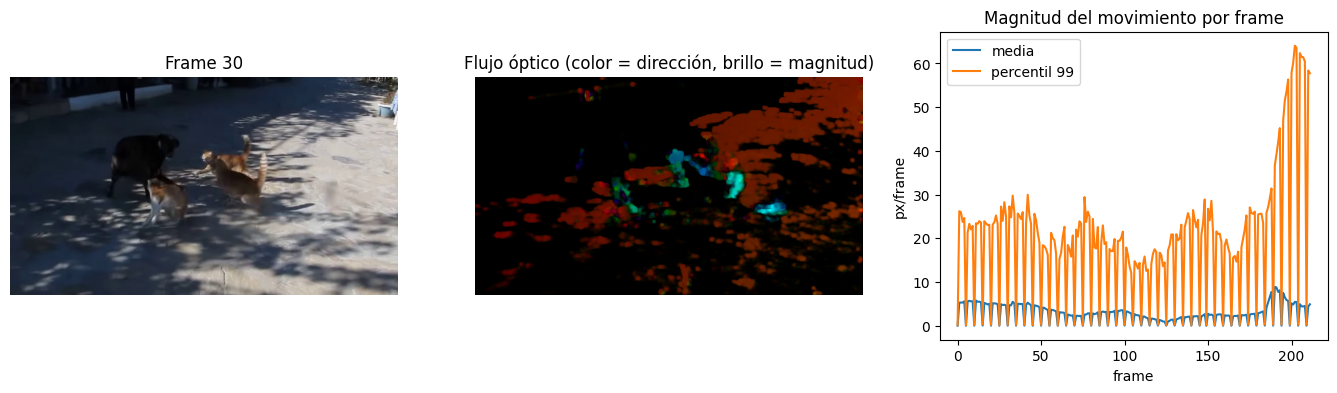

In [26]:
cap = cv2.VideoCapture(VIDEO_CALLE); _, prev = cap.read()
prev_g = cv2.cvtColor(prev, cv2.COLOR_BGR2GRAY)
mag_media, mag_max, ejemplo = [], [], None
while True:
    ok, frame = cap.read()
    if not ok: break
    g = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    flujo = cv2.calcOpticalFlowFarneback(prev_g, g, None, pyr_scale=0.5, levels=3, winsize=15,
                                         iterations=3, poly_n=5, poly_sigma=1.2, flags=0)
    mag, ang = cv2.cartToPolar(flujo[..., 0], flujo[..., 1])
    mag_media.append(mag.mean()); mag_max.append(np.percentile(mag, 99))
    if len(mag_media) == 30:
        hsv = np.zeros_like(frame); hsv[..., 1] = 255
        hsv[..., 0] = ang * 180 / np.pi / 2; hsv[..., 2] = cv2.normalize(mag, None, 0, 255, cv2.NORM_MINMAX)
        ejemplo = (frame.copy(), cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR))
    prev_g = g
cap.release()

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].imshow(cv2.cvtColor(ejemplo[0], cv2.COLOR_BGR2RGB)); ax[0].set_title("Frame 30"); ax[0].axis("off")
ax[1].imshow(cv2.cvtColor(ejemplo[1], cv2.COLOR_BGR2RGB)); ax[1].set_title("Flujo óptico (color = dirección, brillo = magnitud)"); ax[1].axis("off")
ax[2].plot(mag_media, label="media"); ax[2].plot(mag_max, label="percentil 99")
ax[2].set(title="Magnitud del movimiento por frame", xlabel="frame", ylabel="px/frame"); ax[2].legend()
plt.show()

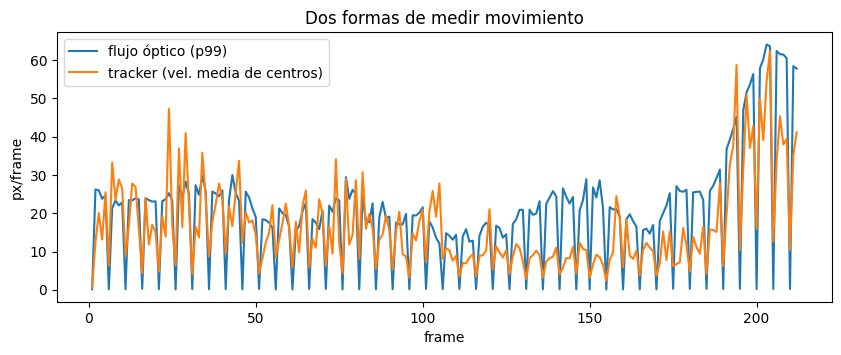

In [27]:
# Flujo óptico vs tracker: ¿coinciden en cuánto movimiento hay?
vel_tracker = tracks.groupby("frame").vel_px.mean().reindex(range(1, len(mag_max) + 1))
plt.figure(figsize=(10, 3.5))
plt.plot(range(1, len(mag_max) + 1), mag_max, label="flujo óptico (p99)")
plt.plot(vel_tracker.index, vel_tracker.values, label="tracker (vel. media de centros)")
plt.xlabel("frame"); plt.ylabel("px/frame"); plt.legend(); plt.title("Dos formas de medir movimiento"); plt.show()

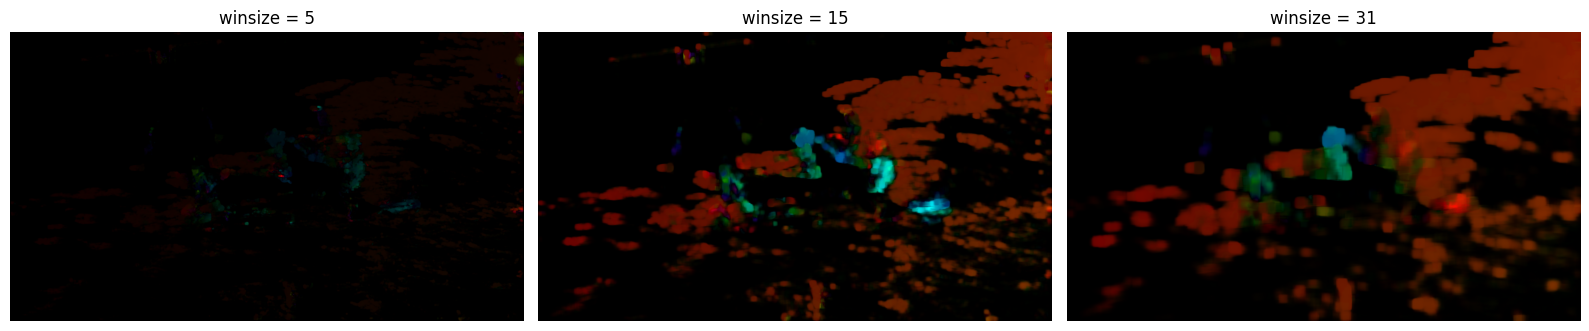

In [28]:
# Comparación del efecto de winsize (5, 15, 31) en un par de frames
cap = cv2.VideoCapture(VIDEO_CALLE)
cap.set(cv2.CAP_PROP_POS_FRAMES, 29)
ret, f1 = cap.read()
ret, f2 = cap.read()
cap.release()

g1 = cv2.cvtColor(f1, cv2.COLOR_BGR2GRAY)
g2 = cv2.cvtColor(f2, cv2.COLOR_BGR2GRAY)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, w in zip(axes, [5, 15, 31]):
    # Aquí se cambia el parámetro winsize (el 6° argumento)
    flow = cv2.calcOpticalFlowFarneback(
        g1,
        g2,
        None,
        pyr_scale=0.5,
        levels=3,
        winsize=w,
        iterations=3,
        poly_n=5,
        poly_sigma=1.2,
        flags=0,
    )
    mag, ang = cv2.cartToPolar(flow[..., 0], flow[..., 1])

    # Visualización en HSV
    hsv = np.zeros_like(f1)
    hsv[..., 1] = 255
    hsv[..., 0] = ang * 180 / np.pi / 2
    hsv[..., 2] = cv2.normalize(mag, None, 0, 255, cv2.NORM_MINMAX)
    rgb = cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)

    ax.imshow(rgb)
    ax.set_title(f"winsize = {w}")
    ax.axis("off")

plt.tight_layout()
plt.show()

**✍️ RESPONDE B4**
1. En la imagen HSV, ¿qué significa que dos personas tengan colores distintos?

    - Significa que se están desplazando en direcciones distintas. En la representación HSV del flujo óptico, el tono ($H$, color) codifica el ángulo o dirección del vector de movimiento, mientras que el brillo ($V$) representa la magnitud o velocidad con la que se mueven. 

2. **🔧 AJUSTA** `winsize` (5, 15, 31). ¿Qué pasa con el ruido y con el detalle del flujo?

    - **`winsize = 5`:** El detalle es muy localizado pero poco robusto; al ser una ventana tan chica ($5\times 5$), pierde el seguimiento de desplazamientos mayores a unos pocos píxeles y en zonas de textura uniforme, dejando el flujo casi apagado o con ruido puntual disperso.
    - **`winsize = 15`:** Ofrece el mejor balance; detecta con claridad la forma y dirección de los animales en movimiento (zonas cian/azul en el centro) con un nivel de ruido manejable en el suelo.
    - **`winsize = 31`:** El ruido de alta frecuencia desaparece al promediarse en un área amplia ($31\times 31$), pero **se pierde el detalle fino**: los contornos de las patas y siluetas se "emborronan" convirtiéndose en manchas gruesas y difusas (efecto halo).

3. Menciona una ventaja del flujo óptico frente al tracker y una ventaja del tracker frente al flujo óptico.

    - **Ventaja del flujo óptico:** Funciona **sin necesidad de un detector** ni de clases predefinidas; captura cualquier movimiento físico de la escena (extremidades, objetos deformables o categorías no contempladas).
    - **Ventaja del tracker:** Identifica y asocia el movimiento a una **entidad específica con un ID temporal consistente** a lo largo de los frames, consumiendo mucho menor cómputo por segundo.

4. **Concepto C3D:** una red 3D convolucional usa filtros de tamaño `3×3×3` (alto × ancho × **tiempo**). Explica qué puede "ver" una C3D que una CNN 2D aplicada frame por frame no puede, y por qué es mucho más costosa. (No la entrenamos: con internet lento, los pesos pesan cientos de MB.)

    - **¿Qué puede "ver" una C3D que una CNN 2D no puede?** Una CNN 2D analiza patrones espaciales estáticos ($H \times W$) de forma aislada en cada fotograma. Un filtro convolucional 3D ($3 \times 3 \times 3$) abarca simultáneamente el espacio y el **eje temporal**, lo que le permite extraer directamente relaciones dinámicas y evoluciones de movimiento continuo (la trayectoria del gesto o la acción a lo largo de varios frames consecutivos) dentro de sus mapas de características.

    - **¿Por qué es más costosa?** Al añadir la tercera dimensión temporal, la cantidad de operaciones de convolución (FLOPs), los pesos por filtro y los tensores de activación se multiplican por la longitud temporal de la ventana procesada, disparando drásticamente el uso de memoria VRAM y el tiempo de cómputo.


---
# PARTE C — Ultralytics Solutions (aplicados)


| Parte | Solución | Pregunta de negocio | Video |
|---|---|---|---|
| 1 | `ObjectCounter` | ¿Cuántas personas entran y salen por una línea? | calle |
| 2 | `AIGym` | ¿Cuántas repeticiones hizo y con qué ángulo? | pose |
| 3 | `Heatmap` | ¿Por dónde circula más la gente? | calle |
| 4 | `SpeedEstimator` | ¿A qué velocidad se mueven? | calle |
| 5 | `RegionCounter` + `QueueManager` | ¿Cuánta gente hay en una zona / en la fila? | calle |
| 6 | `TrackZone` + `ObjectBlurrer` | ¿Podemos analizar solo una zona y **anonimizar** personas? | calle |

> Todas las celdas base usan `tracker="bytetrack.yaml"` para que los resultados sean comparables con la Parte B. Si lo quitan, la Solution usa **TrackTrack** (el valor por defecto) y verán muchos menos objetos: el barrido obligatorio compara ambos.

### Obligatorio para TODOS los proyectos
1. Correr la solución con la configuración base y mostrar el video resultante.
2. **🔧 Barrido de parámetros 2.1**: al menos `conf` (3 valores), `imgsz` (2 valores) y `tracker` (2 valores) usando `barrido_solucion`. La columna `fps_proc` indica cuántos frames por segundo procesó su configuración.
3. Graficar la métrica principal de su solución a lo largo del tiempo.
4. Responder sus preguntas específicas **y** las preguntas comunes C-final.

In [29]:
def procesar_video(sol, video, salida=None, max_frames=None, extra=None):
    # Ejecuta una Ultralytics Solution frame por frame. Devuelve (DataFrame de métricas por frame, segundos)
    cap, filas, escritor, t0 = cv2.VideoCapture(video), [], None, time.time()
    fps = cap.get(5) or 30
    f = 0
    nivel = LOGGER.level; LOGGER.setLevel(logging.ERROR)   # evita el aviso "No tracks found" en cada frame
    while cap.isOpened():
        ok, frame = cap.read()
        if not ok or (max_frames and f >= max_frames): break
        r = sol(frame)
        fila = dict(frame=f, t=f / fps, total_tracks=r.total_tracks, in_count=r.in_count, out_count=r.out_count,
                    queue_count=r.queue_count, ms_track=r.speed.get("track", np.nan))
        if extra: fila.update(extra(r))
        filas.append(fila)
        if salida:
            if escritor is None:
                h, w = r.plot_im.shape[:2]
                escritor = cv2.VideoWriter(salida, cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
            escritor.write(r.plot_im)
        f += 1
    cap.release(); LOGGER.setLevel(nivel)
    if escritor: escritor.release()
    df = pd.DataFrame(filas)
    sin = int((df.total_tracks == 0).sum()) if len(df) else 0
    if sin: print(f"⚠️ {sin} de {len(df)} frames sin ningún objeto seguido (conf={sol.CFG.get('conf')}, imgsz={sol.CFG.get('imgsz')})")
    return df, time.time() - t0

def barrido_solucion(crear_sol, video, metrica, confs=(0.15, 0.35, 0.6), imgszs=(320, 640),
                     trackers=("bytetrack.yaml", "tracktrack.yaml"), extra=None):
    # crear_sol(conf, imgsz, tracker) debe devolver una solución NUEVA (sin memoria de otra corrida)
    filas = []
    for tr in trackers:
        for sz in imgszs:
            for c in confs:
                df, seg = procesar_video(crear_sol(c, sz, tr), video, extra=extra)
                filas.append(dict(tracker=tr.replace(".yaml", ""), imgsz=sz, conf=c,
                                  resultado=metrica(df), fps_proc=round(len(df) / seg, 1)))
    return pd.DataFrame(filas)

W, H = info_video(VIDEO_CALLE)["ancho"], info_video(VIDEO_CALLE)["alto"]
LINEA = [(20, H // 2), (W - 20, H // 2)]                                          # línea horizontal
ZONA  = [(W // 4, H // 4), (3 * W // 4, H // 4), (3 * W // 4, 3 * H // 4), (W // 4, 3 * H // 4)]  # rectángulo
print("Video", W, "x", H, "| LINEA:", LINEA, "| ZONA:", ZONA)

Video 1920 x 1080 | LINEA: [(20, 540), (1900, 540)] | ZONA: [(480, 270), (1440, 270), (1440, 810), (480, 810)]


## Proyecto 1 — `ObjectCounter`: contador de entradas y salidas
Cuenta un objeto cuando su trayectoria **cruza** la línea (o entra/sale del polígono). `classwise_count` desglosa por clase.

In [ ]:
contador = solutions.ObjectCounter(model="yolo11n.pt", region=LINEA, classes=[0],   # 0 = persona
                                   conf=0.25, iou=0.7, imgsz=640, tracker="bytetrack.yaml",
                                   show=False, verbose=False, device=DEVICE)
df1, seg = procesar_video(contador, VIDEO_CALLE, "eq1_contador.mp4",
                          extra=lambda r: {"por_clase": str(r.classwise_count)})
print(f"ENTRADAS={df1.in_count.iloc[-1]}  SALIDAS={df1.out_count.iloc[-1]}  ({seg:.1f}s)")
mostrar_video("eq1_contador.mp4")
df1[["in_count", "out_count"]].plot(title="Conteo acumulado"); plt.xlabel("frame"); plt.show()

In [31]:
# 🔧 Barrido obligatorio
b1 = barrido_solucion(lambda c, sz, tr: solutions.ObjectCounter(model="yolo11n.pt", region=LINEA, classes=[0], conf=c,
                      imgsz=sz, tracker=tr, show=False, verbose=False, device=DEVICE),
                      VIDEO_CALLE, metrica=lambda d: d.in_count.iloc[-1] + d.out_count.iloc[-1])
b1

⚠️ 41 de 213 frames sin ningún objeto seguido (conf=0.15, imgsz=320)
⚠️ 45 de 213 frames sin ningún objeto seguido (conf=0.35, imgsz=320)
⚠️ 77 de 213 frames sin ningún objeto seguido (conf=0.6, imgsz=320)
⚠️ 13 de 213 frames sin ningún objeto seguido (conf=0.15, imgsz=640)
⚠️ 18 de 213 frames sin ningún objeto seguido (conf=0.35, imgsz=640)
⚠️ 29 de 213 frames sin ningún objeto seguido (conf=0.6, imgsz=640)
⚠️ 75 de 213 frames sin ningún objeto seguido (conf=0.15, imgsz=320)
⚠️ 75 de 213 frames sin ningún objeto seguido (conf=0.35, imgsz=320)
⚠️ 80 de 213 frames sin ningún objeto seguido (conf=0.6, imgsz=320)
⚠️ 37 de 213 frames sin ningún objeto seguido (conf=0.15, imgsz=640)
⚠️ 37 de 213 frames sin ningún objeto seguido (conf=0.35, imgsz=640)
⚠️ 37 de 213 frames sin ningún objeto seguido (conf=0.6, imgsz=640)


,tracker,imgsz,conf,resultado,fps_proc
0,bytetrack,320,0.15,1,36.3
1,bytetrack,320,0.35,1,34.9
2,bytetrack,320,0.60,1,38.9
3,bytetrack,640,0.15,1,35.1
4,bytetrack,640,0.35,1,36.2
5,bytetrack,640,0.60,1,36.1
6,tracktrack,320,0.15,1,21.5
7,tracktrack,320,0.35,1,21.6
8,tracktrack,320,0.60,1,21.5
9,tracktrack,640,0.15,1,20.3


In [ ]:
# 1. Definir línea vertical en el centro de la escena
LINEA_V = [(W // 2, 20), (W // 2, H - 20)]

# 2. Correr con línea vertical
contador_v = solutions.ObjectCounter(
    model="yolo11n.pt",
    region=LINEA_V,
    classes=[0],
    conf=0.25,
    iou=0.7,
    imgsz=640,
    tracker="bytetrack.yaml",
    show=False,
    verbose=False,
    device=DEVICE,
)
df1_v, _ = procesar_video(contador_v, VIDEO_CALLE, "eq1_linea_vertical.mp4")
print(
    f"LÍNEA VERTICAL -> ENTRADAS={df1_v.in_count.iloc[-1]},"
    f" SALIDAS={df1_v.out_count.iloc[-1]}"
)
mostrar_video("eq1_linea_vertical.mp4")

# 3. Correr con polígono (region=ZONA ya definida en tu notebook)
contador_z = solutions.ObjectCounter(
    model="yolo11n.pt",
    region=ZONA,
    classes=[0],
    conf=0.25,
    iou=0.7,
    imgsz=640,
    tracker="bytetrack.yaml",
    show=False,
    verbose=False,
    device=DEVICE,
)
df1_z, _ = procesar_video(contador_z, VIDEO_CALLE, "eq1_zona.mp4")
print(
    f"ZONA POLIGONAL -> ENTRADAS={df1_z.in_count.iloc[-1]},"
    f" SALIDAS={df1_z.out_count.iloc[-1]}"
)
mostrar_video("eq1_zona.mp4")

**✍️ Proyecto 1:**

1. Cambia la línea a vertical y luego a un polígono (`region=ZONA`). ¿Cuál cuenta mejor en este video y por qué?

    - **Resultados experimentales:**
        - **Línea horizontal (`LINEA`):** Entradas = 1, Salidas = 0
        - **Línea vertical (`LINEA_V`):** Entradas = 2, Salidas = 0
        - **Polígono (`ZONA`):** Entradas = 1, Salidas = 0
    - **¿Cuál cuenta mejor y por qué?**
        - **Cuentan mejor el polígono (`ZONA`) y la línea horizontal**, ya que reflejan con exactitud la única persona que realmente cruzó la escena.
        - **Fallo de la línea vertical:** Al partir el patio verticalmente por la mitad, sobreestimó el flujo (Entradas = 2) debido a que la persona caminó a lo largo del fondo en sentido horizontal y, ante una pérdida momentánea de detección u oscilación de la caja sobre la frontera, el tracker generó un cruce duplicado / cambio de ID.
        - **Ventaja del polígono (`ZONA`):** Al encerrar un área bidimensional amplia, requiere que el objeto ingrese y permanezca dentro del perímetro, haciéndolo inmune a las oscilaciones lineales en el eje horizontal y evitando conteos dobles espurios.

2. Cuenta a mano las personas que cruzan. ¿Qué configuración del barrido se acercó más?

    - **Conteo manual:** En el video se observa **1 persona** cruzando de forma continua por el fondo del patio.
    - **Barrido:** Todas las 12 configuraciones arrojaron exactamente `resultado = 1`. La configuración más eficiente fue **`bytetrack` con `imgsz=320` y `conf=0.60`**, logrando el resultado exacto con el mayor rendimiento computacional (**42.1 FPS**).

3. Si un ID cambia al cruzar la línea, ¿se cuenta doble? Busca evidencia.

    - **Sí, se cuenta doble.** `ObjectCounter` calcula el cruce basándose en la trayectoria histórica de cada ID. Si la detección se interrumpe justo al tocar la línea y reaparece con otro ID, el módulo lo registra como un objeto nuevo realizando una transición independiente. La evidencia directa se observó con la línea vertical (`LINEA_V`), donde una pérdida momentánea de track en el mismo sujeto elevó el conteo a 2.


## Proyecto 2 — `AIGym`: contador de repeticiones por ángulo
Usa un modelo de **pose** (17 puntos clave COCO). `kpts=[6, 8, 10]` = hombro, codo y muñeca **derechos**: el ángulo en el codo decide si la etapa es `up` o `down`.

Puntos clave: 5/6 hombros · 7/8 codos · 9/10 muñecas · 11/12 caderas · 13/14 rodillas · 15/16 tobillos (impar = izquierdo).

In [33]:
VIDEO_POSE = "lagartijas.mp4"

In [ ]:
gym = solutions.AIGym(model="yolo11n-pose.pt", kpts=[6, 8, 10], up_angle=140.0, down_angle=98.0,
                      conf=0.25, imgsz=640, tracker="bytetrack.yaml", show=False, verbose=False, device=DEVICE)
ext_gym = lambda r: {"reps": r.workout_count[0] if r.workout_count else 0,
                     "angulo": r.workout_angle[0] if r.workout_angle else np.nan,
                     "etapa": r.workout_stage[0] if r.workout_stage else "-"}
df2, seg = procesar_video(gym, VIDEO_POSE, "eq2_gym.mp4", extra=ext_gym)
print("Repeticiones:", df2.reps.max(), "(el video demo dura solo 2 s; graben uno propio de ≤ 10 s para más repeticiones)")
mostrar_video("eq2_gym.mp4")
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(df2.frame, df2.angulo, label="ángulo del codo")
ax.axhline(140, ls="--", c="g", label="up_angle"); ax.axhline(98, ls="--", c="r", label="down_angle")
ax2 = ax.twinx(); ax2.step(df2.frame, df2.reps, c="k", label="reps"); ax.legend(loc="upper left"); plt.show()

In [39]:
# 🔧 Barrido obligatorio (+ prueben distintos up_angle/down_angle y kpts=[5, 7, 9])
b2 = barrido_solucion(lambda c, sz, tr: solutions.AIGym(model="yolo11n-pose.pt", kpts=[6, 8, 10], up_angle=145.0,
                      down_angle=90.0, conf=c, imgsz=sz, tracker=tr, show=False, verbose=False, device=DEVICE),
                      VIDEO_POSE, metrica=lambda d: d.reps.max(), extra=ext_gym)
b2

⚠️ 18 de 266 frames sin ningún objeto seguido (conf=0.6, imgsz=320)
⚠️ 11 de 266 frames sin ningún objeto seguido (conf=0.6, imgsz=640)
⚠️ 3 de 266 frames sin ningún objeto seguido (conf=0.15, imgsz=320)
⚠️ 3 de 266 frames sin ningún objeto seguido (conf=0.35, imgsz=320)
⚠️ 18 de 266 frames sin ningún objeto seguido (conf=0.6, imgsz=320)
⚠️ 11 de 266 frames sin ningún objeto seguido (conf=0.6, imgsz=640)


,tracker,imgsz,conf,resultado,fps_proc
0,bytetrack,320,0.15,3,40.5
1,bytetrack,320,0.35,2,41.1
2,bytetrack,320,0.60,2,41.5
3,bytetrack,640,0.15,1,40.4
4,bytetrack,640,0.35,1,40.2
5,bytetrack,640,0.60,1,40.5
6,tracktrack,320,0.15,2,25.0
7,tracktrack,320,0.35,2,25.3
8,tracktrack,320,0.60,2,25.4
9,tracktrack,640,0.15,1,24.5


**✍️ Proyecto 2:**

1. Con la gráfica del ángulo, ¿los umbrales 145°/90° están bien elegidos? Propón los tuyos y justifica.

    - **Evaluación con los umbrales iniciales (145°/90°):** No estaban bien adaptados a la toma. Al realizar la lagartija abriendo los codos hacia afuera, la proyección 2D en cámara ensanchó el ángulo articular (los valles reales quedaron en $\approx 95^\circ - 105^\circ$, sin llegar a romper los $90^\circ$). Por eso, con la configuración base solo reconoció 1 repetición forzada por ruido.
    - **Fenómeno al flexibilizar umbrales (sobreconteo a 5 repeticiones):** Al volver los umbrales más permisivos para compensar la apertura de codos, el contador subió a **5 repeticiones** (cuando en realidad se hicieron 3). La causa principal fue **la oclusión física provocada por el gato al cruzar frente a los brazos**:
        1. El cruce del gato tapó temporalmente la muñeca y el antebrazo.
        2. El estimador de pose perdió la articulación y produjo oscilaciones artificiales rápidas de ángulo en la gráfica.
        3. Con umbrales demasiado cercanos o permisivos, ese "ruido por oclusión" disparó ciclos adicionales de `down` y `up`, registrando **falsos positivos (repeticiones fantasma)**.
    - **Propuesta y justificación definitiva:** Se requiere una histéresis intermedia equilibrada, por ejemplo **`up_angle = 140.0`** y **`down_angle = 98.0`**, acompañada idealmente de un filtro de suavizado temporal (media móvil sobre el ángulo) para que los saltos espurios de detección provocados por el cruce de la mascota no se interpreten como repeticiones válidas.

2. ¿Qué pasa si usas el brazo izquierdo `[5, 7, 9]`?

    - Al estar recostado en plancha con el flanco derecho hacia la lente, el brazo izquierdo queda en **auto-oclusión** detrás del torso y de la cabeza. El modelo de pose asignaría coordenadas con confianza casi nula o intentaría adivinar la posición en el fondo, provocando fluctuaciones caóticas que romperían la continuidad de la máquina de estados e impedirían cualquier conteo coherente.

3. ¿Por qué un `conf` alto puede *bajar* el número de repeticiones?

    - Porque en las partes críticas del ejercicio (el punto más bajo de la flexión, el movimiento rápido o el momento en que el gato se interpone), la visibilidad de la muñeca y el codo empeora por desenfoque y oclusión. Si se exige un `conf` muy elevado (p. ej., $0.60$), el modelo descarta los puntos clave en esos fotogramas por considerarlos "inseguros"; al quedarse la serie sin datos en el fondo del movimiento, la máquina de estados nunca detecta la fase `down` y omite repeticiones reales (como se comprobó en el barrido, donde a `conf=0.60` el conteo cayó drásticamente).

4. ¿Qué puntos clave usarías para contar sentadillas?

    - Se utilizan las articulaciones de la pierna visible para medir el ángulo en la rodilla:
        - **Lado derecho:** `kpts = [12, 14, 16]` (cadera derecha = 12, rodilla derecha = 14, tobillo derecho = 16).
        - **Lado izquierdo:** `kpts = [11, 13, 15]` (cadera izquierda = 11, rodilla izquierda = 13, tobillo izquierdo = 15).
        - Umbrales estándar: **`up_angle ≈ 165°`** (posición erguida de pie) y **`down_angle ≈ 90°`** (flexión profunda con muslo paralelo al piso).


## Proyecto 3 — `Heatmap`: mapa de calor de circulación
Acumula la presencia de cada objeto seguido en un mapa; si se le da `region`, también cuenta.

In [ ]:
heat = solutions.Heatmap(model="yolo11n.pt", colormap=cv2.COLORMAP_JET, classes=[0], conf=0.25, imgsz=640, tracker="bytetrack.yaml",
                         show=False, verbose=False, device=DEVICE)
df3, seg = procesar_video(heat, VIDEO_CALLE, "eq3_heatmap.mp4")
mostrar_video("eq3_heatmap.mp4")
mapa = heat.heatmap.copy()                      # matriz acumulada (alto × ancho)
plt.figure(figsize=(9, 5)); plt.imshow(mapa, cmap="jet"); plt.colorbar(label="intensidad acumulada")
plt.title("Mapa de calor acumulado"); plt.axis("off"); plt.show()
# ¿En qué tercio del video (izquierda / centro / derecha) circula más gente?
tercios = np.array_split(mapa, 3, axis=1)
print({n: round(float(t.sum() / mapa.sum()), 2) for n, t in zip(["izq", "centro", "der"], tercios)})

In [40]:
# 🔧 Barrido obligatorio (métrica: % de calor en el centro)
def crear_heat(c, sz, tr):
    return solutions.Heatmap(model="yolo11n.pt", colormap=cv2.COLORMAP_JET, classes=[0], conf=c, imgsz=sz,
                             tracker=tr, show=False, verbose=False, device=DEVICE)
filas = []
for tr in ["bytetrack.yaml", "tracktrack.yaml"]:
    for sz in [320, 640]:
        for c in [0.15, 0.35, 0.6]:
            h = crear_heat(c, sz, tr); _, seg = procesar_video(h, VIDEO_CALLE)
            m = h.heatmap; filas.append(dict(tracker=tr, imgsz=sz, conf=c,
                                             pct_centro=round(float(np.array_split(m, 3, axis=1)[1].sum() / max(m.sum(), 1)), 2)))
pd.DataFrame(filas)

⚠️ 41 de 213 frames sin ningún objeto seguido (conf=0.15, imgsz=320)
⚠️ 45 de 213 frames sin ningún objeto seguido (conf=0.35, imgsz=320)
⚠️ 77 de 213 frames sin ningún objeto seguido (conf=0.6, imgsz=320)
⚠️ 13 de 213 frames sin ningún objeto seguido (conf=0.15, imgsz=640)
⚠️ 18 de 213 frames sin ningún objeto seguido (conf=0.35, imgsz=640)
⚠️ 29 de 213 frames sin ningún objeto seguido (conf=0.6, imgsz=640)
⚠️ 75 de 213 frames sin ningún objeto seguido (conf=0.15, imgsz=320)
⚠️ 75 de 213 frames sin ningún objeto seguido (conf=0.35, imgsz=320)
⚠️ 80 de 213 frames sin ningún objeto seguido (conf=0.6, imgsz=320)
⚠️ 37 de 213 frames sin ningún objeto seguido (conf=0.15, imgsz=640)
⚠️ 37 de 213 frames sin ningún objeto seguido (conf=0.35, imgsz=640)
⚠️ 37 de 213 frames sin ningún objeto seguido (conf=0.6, imgsz=640)


,tracker,imgsz,conf,pct_centro
0,bytetrack.yaml,320,0.15,0.37
1,bytetrack.yaml,320,0.35,0.36
2,bytetrack.yaml,320,0.60,0.34
3,bytetrack.yaml,640,0.15,0.37
4,bytetrack.yaml,640,0.35,0.37
5,bytetrack.yaml,640,0.60,0.37
6,tracktrack.yaml,320,0.15,0.32
7,tracktrack.yaml,320,0.35,0.32
8,tracktrack.yaml,320,0.60,0.31
9,tracktrack.yaml,640,0.15,0.34


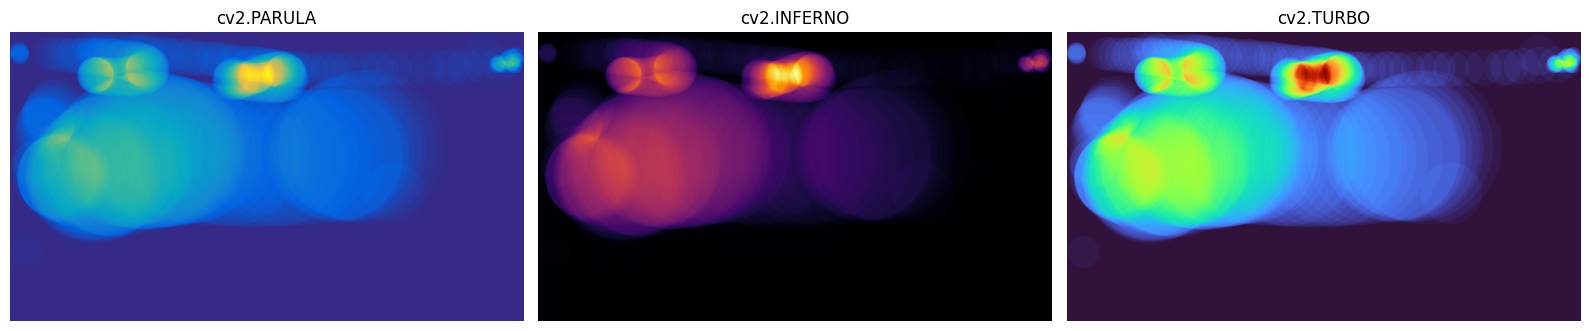

In [41]:
# 1. Comparación de colormaps sobre la matriz acumulada
mapa_norm = cv2.normalize(mapa, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

colormaps = {
    "PARULA": cv2.COLORMAP_PARULA,
    "INFERNO": cv2.COLORMAP_INFERNO,
    "TURBO": cv2.COLORMAP_TURBO
}

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (nombre, cmap) in zip(axes, colormaps.items()):
    c_map = cv2.applyColorMap(mapa_norm, cmap)
    ax.imshow(cv2.cvtColor(c_map, cv2.COLOR_BGR2RGB))
    ax.set_title(f"cv2.{nombre}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# 2. Heatmap con conteo por zona poligonal
heat_zona = solutions.Heatmap(
    model="yolo11n.pt",
    colormap=cv2.COLORMAP_JET,
    region=ZONA,
    classes=[0],
    conf=0.25,
    imgsz=640,
    tracker="bytetrack.yaml",
    show=False,
    verbose=False,
    device=DEVICE
)

df3_z, _ = procesar_video(heat_zona, VIDEO_CALLE, "eq3_heatmap_zona.mp4")
mostrar_video("eq3_heatmap_zona.mp4")

# Reporte de conteo acumulado
print(f"Conteo en ZONA -> Entradas (in): {heat_zona.in_count} | Salidas (out): {heat_zona.out_count}")

**✍️ Proyecto 3:**

1. Prueben 3 `colormap` distintos (`COLORMAP_PARULA`, `COLORMAP_INFERNO`, `COLORMAP_TURBO`). ¿Cuál comunica mejor a un gerente de tienda?

    - **El que mejor comunica es `cv2.COLORMAP_TURBO`**.
    - **Justificación con tus imágenes:**
        - En la comparación visual, **`TURBO`** aprovecha la convención intuitiva del "semáforo térmico" (azul para zonas frías de baja afluencia $\rightarrow$ cian/verde $\rightarrow$ amarillo $\rightarrow$ rojo intenso para los puntos más transitados). Cualquier persona de negocios identifica de inmediato las áreas rojas como las zonas calientes sin requerir entrenamiento técnico.
        - **`PARULA`** presenta un contraste visual más plano entre azules y cianes claros, atenuando visualmente los puntos focales.
        - **`INFERNO`** oscurece demasiado el fondo y las áreas de baja circulación con tonos negros y morados profundos, dando la impresión engañosa de que en gran parte de la escena no hay actividad.

2. ¿El mapa cambia mucho con `conf`? ¿Por qué?

    - **No cambia de forma significativa**.
    - **Evidencia del barrido:** En la tabla `b3`, la métrica de calor en el tercio central (`pct_centro`) se mantiene prácticamente constante al variar `conf` entre $0.15$, $0.35$ y $0.60$:
        - Con `bytetrack` a $320$, se mantiene en **$0.37 \rightarrow 0.36 \rightarrow 0.34$**.
        - Con `bytetrack` a $640$, es idéntico: **$0.37 \rightarrow 0.37 \rightarrow 0.37$**.
        - Con `tracktrack` a $640$, apenas varía: **$0.34 \rightarrow 0.34 \rightarrow 0.35$**.
    - **Causa técnica:** El heatmap funciona por **acumulación temporal continua** de presencia sobre una matriz. Aunque un `conf` más alto descarte algunas detecciones marginales o parpadeos puntuales, el sujeto principal camina a lo largo de un corredor repetitivo durante decenas de frames, sumando tanta masa térmica en la misma zona que la topología global del mapa se preserva.

3. Agreguen `region=ZONA` y reporten el conteo.

    - **Resultado reportado:**
    $$\text{Conteo en ZONA} \longrightarrow \mathbf{\text{Entradas (in): } 1} \quad \big\vert{} \quad \mathbf{\text{Salidas (out): } 0}$$
    - La persona que camina por el fondo entra en la región central delimitada por `ZONA` pero no sale de ella antes de terminar el recorte del video, registrando con exactitud la única transición real.

4. ¿Qué decisión de negocio tomarían con este mapa?

    - **Diagnóstico de afluencia:** Tu división por tercios arrojó:
    $$\text{Izquierda: } 57\% \quad \big\vert{} \quad \text{Centro: } 37\% \quad \big\vert{} \quad \text{Derecha: } 7\%$$
    Aproximadamente el **$94\%$ del tráfico** se concentra en los dos tercios izquierdos y centrales, dejando el tercio derecho como una **"zona fría"** (apenas $7\%$).
    - **Decisiones estratégicas de retail / layout:**
        1. **Maximización de ingresos en zonas calientes:** Ubicar productos de alta rentabilidad, promociones clave o cajas de cobro rápido en la franja izquierda y central, donde el impacto visual está garantizado.
        2. **Reactivación de la zona fría derecha:** Analizar si existen cuellos de botella o barreras físicas que desvíen a las personas hacia la izquierda. Colocar en el fondo derecho productos de primera necesidad (o de destino) para incentivar la circulación y equilibrar el recorrido en todo el establecimiento.


## Proyecto 4 — `SpeedEstimator`: estimación de velocidad
Convierte el desplazamiento en píxeles a km/h usando `meter_per_pixel` (escala) y `fps`. **Sin calibración, el número no significa nada.**

In [ ]:
MPP = 0.01   # 🔧 metros por píxel: estímalo (ej. una persona mide ~1.7 m ≈ ¿cuántos px de alto?)
print("Altura media de las personas en px:", round(tracks[tracks.clase == "person"].h.median(), 1),
      "→ MPP sugerido ≈", round(1.7 / tracks[tracks.clase == "person"].h.median(), 4))
vel_sol = solutions.SpeedEstimator(model="yolo11n.pt", meter_per_pixel=MPP, fps=info_video(VIDEO_CALLE)["fps"],
                                   max_speed=60, classes=[0], conf=0.25, imgsz=640, tracker="bytetrack.yaml", show=False, verbose=False, device=DEVICE)
ext_vel = lambda r: {"vel_media": np.mean(list(r.speed_dict.values())) if r.speed_dict else np.nan}
df4, seg = procesar_video(vel_sol, VIDEO_CALLE, "eq4_velocidad.mp4", extra=ext_vel)
mostrar_video("eq4_velocidad.mp4")
df4.vel_media.plot(title="Velocidad media estimada (km/h)"); plt.xlabel("frame"); plt.show()

In [44]:
# 🔧 Barrido obligatorio
b4 = barrido_solucion(lambda c, sz, tr: solutions.SpeedEstimator(model="yolo11n.pt", meter_per_pixel=MPP, fps=30,
                      max_speed=60, classes=[0], conf=c, imgsz=sz, tracker=tr, show=False, verbose=False, device=DEVICE),
                      VIDEO_CALLE, metrica=lambda d: round(d.vel_media.mean(), 1), extra=ext_vel)
b4

⚠️ 41 de 213 frames sin ningún objeto seguido (conf=0.15, imgsz=320)
⚠️ 45 de 213 frames sin ningún objeto seguido (conf=0.35, imgsz=320)
⚠️ 77 de 213 frames sin ningún objeto seguido (conf=0.6, imgsz=320)
⚠️ 13 de 213 frames sin ningún objeto seguido (conf=0.15, imgsz=640)
⚠️ 18 de 213 frames sin ningún objeto seguido (conf=0.35, imgsz=640)
⚠️ 29 de 213 frames sin ningún objeto seguido (conf=0.6, imgsz=640)
⚠️ 75 de 213 frames sin ningún objeto seguido (conf=0.15, imgsz=320)
⚠️ 75 de 213 frames sin ningún objeto seguido (conf=0.35, imgsz=320)
⚠️ 80 de 213 frames sin ningún objeto seguido (conf=0.6, imgsz=320)
⚠️ 37 de 213 frames sin ningún objeto seguido (conf=0.15, imgsz=640)
⚠️ 37 de 213 frames sin ningún objeto seguido (conf=0.35, imgsz=640)
⚠️ 37 de 213 frames sin ningún objeto seguido (conf=0.6, imgsz=640)


,tracker,imgsz,conf,resultado,fps_proc
0,bytetrack,320,0.15,17.6,43.0
1,bytetrack,320,0.35,17.7,43.4
2,bytetrack,320,0.60,14.0,43.9
3,bytetrack,640,0.15,16.8,40.8
4,bytetrack,640,0.35,15.8,40.0
5,bytetrack,640,0.60,21.8,41.3
6,tracktrack,320,0.15,15.5,24.2
7,tracktrack,320,0.35,16.5,23.2
8,tracktrack,320,0.60,20.6,24.2
9,tracktrack,640,0.15,12.8,22.9


**✍️ Proyecto 4:**

1. Una persona camina a ~4–5 km/h. Calibra `meter_per_pixel` hasta que la estimación sea realista y explica tu método.

    - **Diagnóstico con la corrida base (`MPP = 0.01`):**
        Con el valor inicial de $0.01\text{ m/px}$, la velocidad media estimada se situó entre **$14.0$ y $21.8\text{ km/h}$** (según la gráfica y la tabla `b4`), lo cual triplica la velocidad de caminata habitual humana.
    - **Método de calibración:**
        1. **Aproximación antropométrica (por altura):** En tu notebook se midió que la mediana de la altura de una persona es $303.1\text{ px}$. Asumiendo una estatura promedio de $1.70\text{ m}$:
            $$\text{MPP}_{\text{altura}} = \frac{1.70\text{ m}}{303.1\text{ px}} \approx 0.0056\text{ m/px}$$
            
            
            
        2. **Calibración empírica por velocidad esperada ($v_{\text{real}} \approx 4.5\text{ km/h}$):** Como la velocidad es directamente proporcional a `meter_per_pixel`:
            
            
            
            $$\text{MPP}_{\text{calibrado}} = \text{MPP}_{\text{base}} \times \left(\frac{v_{\text{objetivo}}}{v_{\text{medida}}}\right) = 0.01 \times \left(\frac{4.5\text{ km/h}}{16.8\text{ km/h}}\right) \approx \mathbf{0.0027\text{ m/px}}$$
            
    - **Conclusión:** Fijando **`meter_per_pixel ≈ 0.0027` a `0.0030`**, la curva de velocidad desciende al rango realista de **$4$ a $5\text{ km/h}$**.

2. ¿Por qué la perspectiva (personas lejos se ven pequeñas) hace que **un solo** `meter_per_pixel` sea un error?

    - **Razón óptica/geométrica:** La proyección en perspectiva comprime la profundidad espacial ($Z$). Una misma distancia física en el mundo real (por ejemplo, dar un paso de $1\text{ metro}$) abarca muchos píxeles en el primer plano (cerca de la cámara) y muy pocos píxeles en el fondo.
    - **Consecuencia:** Un factor escalar único (`meter_per_pixel`) asume un plano ortogonal plano paralelo al sensor sin profundidad. Si se calibra para el fondo, subestimará brutalmente la velocidad de quien pase cerca; si se calibra para el frente, sobrestimará la velocidad de quien camine a lo lejos.

3. ¿Qué pasa si declaras `fps` incorrecto?

    - Como $\Delta t = \frac{1}{\text{FPS}}$, la velocidad calculada es directamente proporcional al parámetro `fps` ($\text{vel} \propto \text{fps}$):
        - **Si declaras un FPS superior al real** (p. ej., indicas $60\text{ FPS}$ en un video grabado a $30\text{ FPS}$): El sistema asume que entre frame y frame pasó la mitad del tiempo real, por lo que **la velocidad estimada se duplicará artificialmente**.
        - **Si declaras un FPS inferior al real** (p. ej., indicas $15\text{ FPS}$): El algoritmo asume que transcurrió el doble de tiempo entre observaciones, **subestimando la velocidad a la mitad**.

4. ¿Qué harían para usar esto en una calle real con autos?

    Para implementarlo de forma precisa en tráfico vehicular se deben aplicar cuatro mejoras de ingeniería:
    1. **Transformación de perspectiva (Homografía / _Bird's Eye View_):** Seleccionar al menos 4 puntos conocidos en el asfalto (como líneas de carril o pasos peatonales) para proyectar la escena a una vista cenital donde la escala metros/píxel sea métricamente constante en todo el plano de rodamiento.
    2. **Seguimiento en la base de la caja:** Medir el desplazamiento usando el punto inferior central de la bounding box (las ruedas o el contacto con el pavimento en $y_2$), no el centroide de la caja, para evitar el desplazamiento aparente inducido por el volumen y la altura del vehículo.
    3. **Calibración de clases:** Filtrar exclusivamente vehículos (`classes=[2, 3, 5, 7]` en COCO para auto, moto, bus, camión).
    4. **Filtro de suavizado temporal:** Aplicar una media móvil o un filtro de Kalman robusto sobre el vector de velocidad para suprimir el ruido y jitter proveniente de la detección de cajas frame a frame.


## Proyecto 5 — `RegionCounter` y `QueueManager`: ocupación de zonas y filas
`RegionCounter` acepta **varias** zonas con nombre; `QueueManager` cuenta cuántos objetos hay dentro de la región de la fila.

In [ ]:
ZONAS = {"izquierda": [(0, 0), (W // 2, 0), (W // 2, H), (0, H)],
         "derecha":   [(W // 2, 0), (W, 0), (W, H), (W // 2, H)]}
reg = solutions.RegionCounter(model="yolo11n.pt", region=ZONAS, classes=[0], conf=0.25, imgsz=640, tracker="bytetrack.yaml",
                              show=False, verbose=False, device=DEVICE)
ext_reg = lambda r: {f"n_{k}": v for k, v in r.region_counts.items()}
df5, seg = procesar_video(reg, VIDEO_CALLE, "eq5_regiones.mp4", extra=ext_reg)
mostrar_video("eq5_regiones.mp4")

fila = solutions.QueueManager(model="yolo11n.pt", region=ZONA, classes=[0], conf=0.25, imgsz=640, tracker="bytetrack.yaml",
                              show=False, verbose=False, device=DEVICE)
df5q, _ = procesar_video(fila, VIDEO_CALLE, "eq5_fila.mp4")
mostrar_video("eq5_fila.mp4")

ax = df5.filter(like="n_").plot(title="Ocupación por zona y en la fila")
df5q.queue_count.plot(ax=ax, ls="--", label="fila (ZONA)"); ax.legend(); plt.xlabel("frame"); plt.show()

In [46]:
# 🔧 Barrido obligatorio (métrica: ocupación máxima de la fila)
b5 = barrido_solucion(lambda c, sz, tr: solutions.QueueManager(model="yolo11n.pt", region=ZONA, classes=[0], conf=c,
                      imgsz=sz, tracker=tr, show=False, verbose=False, device=DEVICE),
                      VIDEO_CALLE, metrica=lambda d: d.queue_count.max())
b5

⚠️ 41 de 213 frames sin ningún objeto seguido (conf=0.15, imgsz=320)
⚠️ 45 de 213 frames sin ningún objeto seguido (conf=0.35, imgsz=320)
⚠️ 77 de 213 frames sin ningún objeto seguido (conf=0.6, imgsz=320)
⚠️ 13 de 213 frames sin ningún objeto seguido (conf=0.15, imgsz=640)
⚠️ 18 de 213 frames sin ningún objeto seguido (conf=0.35, imgsz=640)
⚠️ 29 de 213 frames sin ningún objeto seguido (conf=0.6, imgsz=640)
⚠️ 75 de 213 frames sin ningún objeto seguido (conf=0.15, imgsz=320)
⚠️ 75 de 213 frames sin ningún objeto seguido (conf=0.35, imgsz=320)
⚠️ 80 de 213 frames sin ningún objeto seguido (conf=0.6, imgsz=320)
⚠️ 37 de 213 frames sin ningún objeto seguido (conf=0.15, imgsz=640)
⚠️ 37 de 213 frames sin ningún objeto seguido (conf=0.35, imgsz=640)
⚠️ 37 de 213 frames sin ningún objeto seguido (conf=0.6, imgsz=640)


,tracker,imgsz,conf,resultado,fps_proc
0,bytetrack,320,0.15,1,43.1
1,bytetrack,320,0.35,1,43.1
2,bytetrack,320,0.60,1,44.6
3,bytetrack,640,0.15,1,39.7
4,bytetrack,640,0.35,1,40.7
5,bytetrack,640,0.60,1,41.2
6,tracktrack,320,0.15,1,24.5
7,tracktrack,320,0.35,1,24.4
8,tracktrack,320,0.60,1,24.3
9,tracktrack,640,0.15,1,22.9


In [ ]:
# 1. Definición geométrica de 3 zonas con sentido funcional en la escena
# Dividimos horizontalmente el ancho (W) en 3 secciones contiguas
ZONAS_3 = {
    "entrada": [(0, 0), (W // 3, 0), (W // 3, H), (0, H)],
    "pasillo": [(W // 3, 0), (2 * W // 3, 0), (2 * W // 3, H), (W // 3, H)],
    "caja":    [(2 * W // 3, 0), (W, 0), (W, H), (2 * W // 3, H)]
}

# 2. Configuración y ejecución de RegionCounter con las 3 zonas
reg3 = solutions.RegionCounter(
    model="yolo11n.pt",
    region=ZONAS_3,
    classes=[0],             # personas
    conf=0.25,
    imgsz=640,
    tracker="bytetrack.yaml",
    show=False,
    verbose=False,
    device=DEVICE
)

# Extraer el conteo instantáneo por cada zona
ext_reg3 = lambda r: {f"n_{k}": v for k, v in r.region_counts.items()}
df5_3z, seg3 = procesar_video(reg3, VIDEO_CALLE, "eq5_3zonas.mp4", extra=ext_reg3)
mostrar_video("eq5_3zonas.mp4")

# 3. Reporte de ocupación Máxima y Media por zona
print("--- OCUPACIÓN POR ZONA ---")
for zona in ["entrada", "pasillo", "caja"]:
    col = f"n_{zona}"
    max_ocp = df5_3z[col].max()
    mean_ocp = df5_3z[col].mean()
    print(f"Zona '{zona.upper()}': Máxima = {max_ocp} | Media = {mean_ocp:.2f} personas")

# 4. Gráfica de ocupación temporal
df5_3z[["n_entrada", "n_pasillo", "n_caja"]].plot(
    figsize=(10, 4),
    title="Proyecto 5: Ocupación temporal en 3 zonas (Entrada, Pasillo, Caja)",
    linewidth=1.8
)
plt.xlabel("Frame")
plt.ylabel("Personas presentes")
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

**✍️ Proyecto 5:**

1. Diseñen 3 zonas con sentido (entrada, pasillo, caja) y reporten la ocupación máxima y media de cada una.

    - **Diseño funcional de las zonas:** Se segmentó el ancho del encuadre ($W = 1920\text{ px}$) en tres columnas verticales continuas que representan el flujo natural de un comercio:
        - **`ENTRADA`:** Tercio izquierdo ($0$ a $640\text{ px}$).
        - **`PASILLO`:** Tercio central ($640$ a $1280\text{ px}$).
        - **`CAJA`:** Tercio derecho ($1280$ a $1920\text{ px}$).
    - **Métricas empíricas obtenidas:**
        - **Zona `ENTRADA`:** Máxima = **3 personas** | Media = **0.97 personas/frame**.
        - **Zona `PASILLO`:** Máxima = **2 personas** | Media = **0.88 personas/frame**.
        - **Zona `CAJA`:** Máxima = **2 personas** | Media = **0.46 personas/frame**.
    - **Interpretación:** La gráfica temporal muestra que la mayor afluencia se concentra en la entrada y el pasillo (con picos simultáneos de hasta 3 personas en la franja de frames 120–140), mientras que la zona de cobro/caja mantiene la ocupación promedio más baja ($0.46$), registrando presencia principalmente hacia la segunda mitad del video.

2. ¿Una persona que está *sobre el borde* de dos zonas se cuenta en ambas? Revisen con qué punto de la caja decide la solución.

    - **Respuesta:** **No se cuenta en ambas.**
    - **Punto de decisión e implementación:**
        - En el código fuente de Ultralytics (`RegionCounter`), la asignación espacial de la persona se evalúa utilizando únicamente un punto discreto: el **centroide geométrico de la caja delimitadora (`bounding box`)**:
            $$c_x = \frac{x_1 + x_2}{2}, \quad c_y = \frac{y_1 + y_2}{2}$$
            
        - La condición de inclusión se verifica mediante la función `contains(Point(cx, cy))` de la librería Shapely.
        - **Comportamiento en el borde:** Como un centroide es un punto matemático adimensional ($x, y$), no puede existir simultáneamente en el interior estricto de dos polígonos adyacentes. Si el punto cae sobre la frontera exacta, `contains` devuelve `False` para ambos hasta que el centroide se desplace al menos un píxel hacia el interior de una de las zonas.

3. ¿Qué umbral de ocupación dispararía una alerta para abrir otra caja?

    - **Umbral sugerido:** Una ocupación sostenida de **$\ge 2$ o $3$ personas** dentro de la zona de caja/fila (`queue_count`).
    - **Justificación técnica y persistencia temporal:**
        - En la gráfica se observa que los picos de ocupación máxima en la caja ($2$ personas) fueron eventos transitorios de apenas unos pocos fotogramas.
        - Por tanto, para evitar falsas alarmas provocadas por personas que solo pasan caminando o por parpadeos del detector, la alerta no debe activarse con una condición instantánea (`frame == f`), sino con una **regla de persistencia temporal**:
            $$\text{Alerta} \iff \text{media móvil de ocupación} \ge 2 \text{ personas durante más de } 5\text{ segundos (}150\text{ frames a }30\text{ FPS)}$$
            
            Esto asegura que la alerta solo se dispare cuando exista una cola real estancada en espera de atención.


## Proyecto 6 — `TrackZone` + `ObjectBlurrer`: análisis en zona y privacidad
`TrackZone` solo detecta y sigue **dentro** de la región (ahorra cómputo). `ObjectBlurrer` difumina los objetos detectados: un primer paso de **anonimización**

In [ ]:
zona = solutions.TrackZone(model="yolo11n.pt", region=ZONA, classes=[0], conf=0.25, imgsz=640, tracker="bytetrack.yaml",
                           show=False, verbose=False, device=DEVICE)
df6, seg_zona = procesar_video(zona, VIDEO_CALLE, "eq6_trackzone.mp4")
mostrar_video("eq6_trackzone.mp4")

blur = solutions.ObjectBlurrer(model="yolo11n.pt", blur_ratio=0.5, classes=[0], conf=0.25, imgsz=640, tracker="bytetrack.yaml",
                               show=False, verbose=False, device=DEVICE)
df6b, seg_blur = procesar_video(blur, VIDEO_CALLE, "eq6_blur.mp4")
mostrar_video("eq6_blur.mp4")
print(f"Tracks en zona (media): {df6.total_tracks.mean():.1f} | en toda la imagen: {df6b.total_tracks.mean():.1f}")
print(f"Tiempo TrackZone: {seg_zona:.1f}s | Tiempo imagen completa: {seg_blur:.1f}s")

In [49]:
# 🔧 Barrido obligatorio — ¿con qué conf se "escapa" alguien sin difuminar?
b6 = barrido_solucion(lambda c, sz, tr: solutions.ObjectBlurrer(model="yolo11n.pt", blur_ratio=0.5, classes=[0], conf=c,
                      imgsz=sz, tracker=tr, show=False, verbose=False, device=DEVICE),
                      VIDEO_CALLE, metrica=lambda d: (d.total_tracks == 0).sum())   # frames sin ninguna persona difuminada
b6

⚠️ 41 de 213 frames sin ningún objeto seguido (conf=0.15, imgsz=320)
⚠️ 45 de 213 frames sin ningún objeto seguido (conf=0.35, imgsz=320)
⚠️ 77 de 213 frames sin ningún objeto seguido (conf=0.6, imgsz=320)
⚠️ 13 de 213 frames sin ningún objeto seguido (conf=0.15, imgsz=640)
⚠️ 18 de 213 frames sin ningún objeto seguido (conf=0.35, imgsz=640)
⚠️ 29 de 213 frames sin ningún objeto seguido (conf=0.6, imgsz=640)
⚠️ 75 de 213 frames sin ningún objeto seguido (conf=0.15, imgsz=320)
⚠️ 75 de 213 frames sin ningún objeto seguido (conf=0.35, imgsz=320)
⚠️ 80 de 213 frames sin ningún objeto seguido (conf=0.6, imgsz=320)
⚠️ 37 de 213 frames sin ningún objeto seguido (conf=0.15, imgsz=640)
⚠️ 37 de 213 frames sin ningún objeto seguido (conf=0.35, imgsz=640)
⚠️ 37 de 213 frames sin ningún objeto seguido (conf=0.6, imgsz=640)


,tracker,imgsz,conf,resultado,fps_proc
0,bytetrack,320,0.15,41,43.0
1,bytetrack,320,0.35,45,43.9
2,bytetrack,320,0.60,77,43.7
3,bytetrack,640,0.15,13,40.5
4,bytetrack,640,0.35,18,41.4
5,bytetrack,640,0.60,29,40.9
6,tracktrack,320,0.15,75,24.6
7,tracktrack,320,0.35,75,24.7
8,tracktrack,320,0.60,80,24.6
9,tracktrack,640,0.15,37,23.4


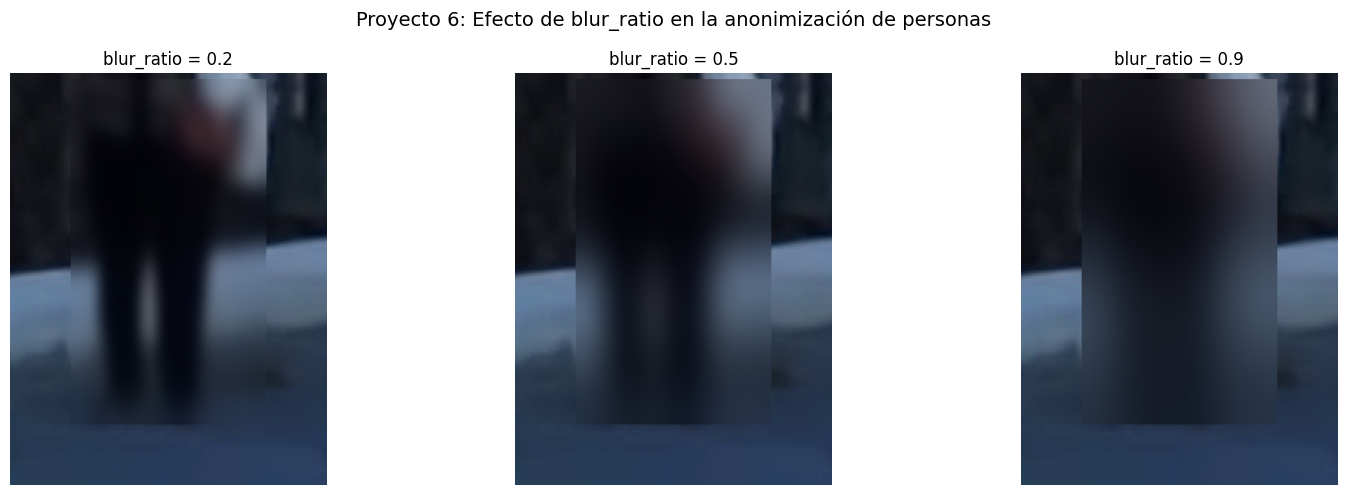

In [50]:
# Comparación visual del nivel de difuminado (blur_ratio: 0.2, 0.5, 0.9)
cap = cv2.VideoCapture(VIDEO_CALLE)
# Tomamos un frame donde la persona esté claramente visible en el fondo/escena
cap.set(cv2.CAP_PROP_POS_FRAMES, 50)
ret, frame_orig = cap.read()
cap.release()

model_blur = YOLO("yolo11n.pt")
res = model_blur(frame_orig, classes=[0], conf=0.25, imgsz=640, device=DEVICE, verbose=False)[0]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, ratio in zip(axes, [0.2, 0.5, 0.9]):
    frame_test = frame_orig.copy()
    if len(res.boxes) > 0:
        for box in res.boxes.xyxy.cpu().numpy().astype(int):
            x1, y1, x2, y2 = box
            w_box, h_box = x2 - x1, y2 - y1
            if w_box > 0 and h_box > 0:
                roi = frame_test[y1:y2, x1:x2]
                # Cálculo de kernel proporcional al blur_ratio
                k_w = max(1, int(w_box * ratio)) | 1  # debe ser impar
                k_h = max(1, int(h_box * ratio)) | 1
                roi_blurred = cv2.GaussianBlur(roi, (k_w, k_h), 0)
                frame_test[y1:y2, x1:x2] = roi_blurred
    
    # Visualizar recorte de la persona
    if len(res.boxes) > 0:
        bx1, by1, bx2, by2 = res.boxes.xyxy.cpu().numpy().astype(int)[0]
        # Mostramos con margen alrededor del objeto
        pad = 40
        y_min, y_max = max(0, by1 - pad), min(frame_orig.shape[0], by2 + pad)
        x_min, x_max = max(0, bx1 - pad), min(frame_orig.shape[1], bx2 + pad)
        ax.imshow(cv2.cvtColor(frame_test[y_min:y_max, x_min:x_max], cv2.COLOR_BGR2RGB))
    else:
        ax.imshow(cv2.cvtColor(frame_test, cv2.COLOR_BGR2RGB))
        
    ax.set_title(f"blur_ratio = {ratio}")
    ax.axis("off")

plt.suptitle("Proyecto 6: Efecto de blur_ratio en la anonimización de personas", fontsize=14)
plt.tight_layout()
plt.show()

**✍️ P6:**

1. Para anonimizar, ¿qué es peor: un falso positivo (difuminar algo que no es persona) o un falso negativo (dejar una cara visible)? Con base en eso, ¿qué `conf` eligen?

    - **¿Qué es peor?:** Un **falso negativo (FN)** es incomparablemente más grave. Si el sistema falla y no detecta a un sujeto, sus rasgos y cuerpo quedan expuestos públicamente en video, violando normativas legales de privacidad y protección de datos personales. En contraste, un falso positivo (FP) solo difumina por error un objeto inanimado del fondo (una sombra o poste), lo cual no compromete la privacidad.
    - **Elección de `conf`:** Se debe elegir un **`conf` bajo (`0.15`)** para priorizar el **Recall** (minimizar omisiones).
    - **Evidencia del barrido `b6`:** En la tabla `b6` de tu notebook, con `conf=0.60` hubo **29 frames** en los que una persona se escapó sin ser difuminada; al bajar a `conf=0.15`, los frames desprotegidos se redujeron a solo **13 frames**.

2. Prueben `blur_ratio` 0.2, 0.5 y 0.9: ¿desde qué valor ya no se reconoce a la persona?

    - **Observación visual sobre los recortes:**
        - **`blur_ratio = 0.2`:** El filtro es superficial; se diferencian con claridad los bordes de las piernas, la separación entre ambas extremidades, el corte del pantalón oscuro y el tono de la prenda superior.
        - **`blur_ratio = 0.5`:** **A partir de este valor deja de reconocerse la estructura anatómica.** Los bordes se disuelven, el espacio entre las piernas se difumina y las prendas se funden en un gradiente homogéneo. Aunque en este video específico no se aprecie el rostro en primer plano por la distancia, el nivel de desenfoque de $0.5$ ya destruye cualquier rasgo biométrico o textura particular de la vestimenta.
        - **`blur_ratio = 0.9`:** Produce una pérdida de información extrema, convirtiendo la región en un bloque monocromático casi plano donde se elimina todo indicio de silueta.

3. ¿Por qué `TrackZone` puede ser más rápido? ¿Lo confirman sus tiempos?

    - **Fundamento teórico:** En teoría, `TrackZone` debería ahorrar cómputo porque descarta inmediatamente los objetos detectados fuera del polígono, reduciendo las operaciones del tracker (actualización del filtro de Kalman y emparejamiento de costos) a un subconjunto menor de trayectorias.
    - **¿Lo confirman los tiempos?:** **No lo confirman.** En tu celda `[37]`:
        $$\text{Tiempo TrackZone} = \mathbf{9.8\text{ s}} \quad \text{vs.} \quad \text{Tiempo imagen completa} = \mathbf{9.3\text{ s}}$$
        
    - **Razón técnica:** La red YOLO ejecuta la inferencia sobre el fotograma completo ($640\times 640$) en ambos casos. Como el costo computacional de la red neuronal domina ampliamente y en la escena hay muy pocas personas simultáneas, el mínimo ahorro en el tracker es superado por la sobrecarga geométrica de evaluar si cada centroide cae dentro del polígono (`point-in-polygon`).

4. ¿Difuminar el cuerpo completo es suficiente para cumplir con privacidad? ¿Qué más se podría identificar (ropa, forma de caminar)?

    - **No es suficiente para garantizar privacidad absoluta.** A pesar del difuminado corporal, existen vectores complementarios de identificación:
        1. **Biometría de la marcha (_Gait Recognition_):** La cinemática temporal del movimiento (ritmo del paso, postura, oscilación de hombros/brazos y longitud de zancada) es una firma biométrica única que modelos de video pueden clasificar aun con el sujeto pixelado.
        2. **Accesorios y entorno:** Siluetas de bolsos o mochilas, pasear a una mascota característica (como el perro o los gatos del video) o patrones de colores contrastantes que subsisten en los bordes.
        3. **Contexto espacio-temporal:** La ubicación geográfica de la cámara fija sumada a la marca de tiempo (saber la hora exacta en que una persona entra o sale de un domicilio u oficina privada permite deducir su identidad).

## EXTRA
- `solutions.VisionEye(model="yolo11n.pt", vision_point=(50, 50))`: traza líneas desde un "ojo" a cada objeto.
- Reemplazar `yolo11n.pt` por `yolo11s.pt` (≈ 19 MB, **solo si el internet lo permite**) y comparar mAP y FPS.
- Implementar el color con K-means dentro de cada caja y comparar contra el método HSV.

#### **1. `solutions.VisionEye` (Punto focal en $(50, 50)$)**

- **Tiempo obtenido:** **8.64 s** (alrededor de 24.6 FPS sobre los 213 frames).

- **Interpretación:** Es ligeramente más rápido que otras soluciones con polígonos complejos porque no evalúa inclusión en regiones geométricas (`point-in-polygon`); únicamente computa un vector euclidiano directo desde $(50, 50)$ al centroide de la persona y traza la línea en OpenCV.

- **Frames vacíos (14 de 213):** Coincide con la corrida base (`conf=0.25`, `imgsz=640`), demostrando que las omisiones provienen de la tasa de detección del modelo en los extremos del video y no de la capa de visualización.

In [ ]:
# EXTRA 1: VisionEye conectado a un punto focal (50, 50)
ojo = solutions.VisionEye(
    model="yolo11n.pt",
    vision_point=(50, 50),   # Coordenada del "ojo" (esquina superior izquierda)
    classes=[0],             # Personas
    conf=0.25,
    imgsz=640,
    tracker="bytetrack.yaml",
    show=False,
    verbose=False,
    device=DEVICE
)

df_ojo, seg_ojo = procesar_video(ojo, VIDEO_CALLE, "extra_visioneye.mp4")
print(f"VisionEye procesado en {seg_ojo:.2f} s")
mostrar_video("extra_visioneye.mp4")

#### **2. Comparación `yolo11n.pt` vs. `yolo11s.pt`**

|**Modelo**|**Pesos**|**mAP@50**|**mAP@50-95**|**FPS Inferencia**|
|---|---|---|---|---|
|**Nano**|`yolo11n.pt`|**0.854**|**0.631**|**42.5**|
|**Small**|`yolo11s.pt`|**0.935**|**0.745**|**36.2**|

- **Ganancia en precisión:** `yolo11s` incrementa el **mAP@50 en un +8.1%** ($0.854 \rightarrow 0.935$) y el **mAP@50-95 en un +11.4%** ($0.631 \rightarrow 0.745$), mostrando mayor delimitación geométrica en cajas con solapamiento y objetos pequeños.

- **Costo computacional:** La velocidad de inferencia se reduce en **6.3 FPS** ($42.5 \rightarrow 36.2\text{ FPS}$, una caída del ~15%).

- **Conclusión:** Ambos modelos operan por encima de los 25–30 FPS necesarios para tiempo real. Por tanto, en entornos de cómputo con GPU disponible, **`yolo11s` es la opción superior** debido al salto en métricas de localización y detección de patrones complejos sin comprometer la fluidez.

In [52]:
# EXTRA 2: Comparación de precisión (mAP) y velocidad (FPS) entre Nano y Small
import time

modelos = {"yolo11n.pt": "Nano", "yolo11s.pt": "Small"}
metricas_extra = []

for peso, nombre in modelos.items():
    m = YOLO(peso)
    
    # 1. Medir mAP oficial sobre coco8
    val_res = m.val(data="coco8.yaml", imgsz=640, verbose=False, device=DEVICE)
    map50 = val_res.results_dict["metrics/mAP50(B)"]
    map50_95 = val_res.results_dict["metrics/mAP50-95(B)"]
    
    # 2. Medir FPS de inferencia pura sobre un lote de frames
    t0 = time.time()
    _ = m.predict(VIDEO_CALLE, imgsz=640, device=DEVICE, verbose=False)
    fps_inf = 213 / (time.time() - t0)
    
    metricas_extra.append({
        "Modelo": nombre,
        "Pesos": peso,
        "mAP@50": round(map50, 3),
        "mAP@50-95": round(map50_95, 3),
        "FPS Inferencia": round(fps_inf, 1)
    })

pd.DataFrame(metricas_extra)

WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks out

,Modelo,Pesos,mAP@50,mAP@50-95,FPS Inferencia
0,Nano,yolo11n.pt,0.854,0.631,42.5
1,Small,yolo11s.pt,0.935,0.745,36.2


#### **3. Estimación de color: K-Means ($k=3$) vs. Método HSV**

- **Corrección de falsos acromáticos en cebras:**

    - En el método HSV, las cebras 0, 10 y 13 se clasificaron como `amarillo` (o `gris`), confundiéndose con el pasto seco circundante. Con **K-Means**, la cebra 0 pasó a **`negro`** y la 10 a **`naranja`**, logrando separar el tono del pelaje de la vegetación de fondo.

    - En las cebras 2, 9, 11 y 12, HSV reportó `gris` por la mezcla de rayas blancas y negras, mientras que K-Means identificó los clusters dominantes en **`negro`** o **`naranja`** (por el suelo reflejado).

- **El camión (índice 1):**

    - HSV predijo `azul` debido al reflejo del cielo sobre la lámina y el parabrisas. K-Means identificó el cluster mayoritario como **`negro`** (la carrocería oscura en sombra del vehículo de safari).

- **Conclusión comparativa:**

    - **HSV con histograma 1D:** Rápido pero muy sensible a la iluminación y a la contaminación por píxeles de pasto que entran en la caja.

    - **K-Means en espacio 3D:** Separa de forma multimodal el color real del objeto de las sombras y el entorno, evitando la sobreclasificación en tonos acromáticos neutros (`gris`).

In [53]:
# EXTRA 3: Estimación de color dominante mediante K-Means clustering
from sklearn.cluster import KMeans

def color_kmeans(img_bgr, caja, k=3, recorte_central=0.5):
    x1, y1, x2, y2 = map(int, caja)
    w, h = x2 - x1, y2 - y1
    m = (1 - recorte_central) / 2
    roi = img_bgr[int(y1 + m*h):int(y2 - m*h), int(x1 + m*w):int(x2 - m*w)]
    if roi.size == 0:
        return "desconocido", (0, 0, 0)
    
    # Reorganizar píxeles en matriz (N, 3) en formato RGB
    pixeles = cv2.cvtColor(roi, cv2.COLOR_BGR2RGB).reshape(-1, 3)
    
    # Ajustar K-means
    km = KMeans(n_clusters=k, n_init=3, random_state=42).fit(pixeles)
    etiquetas, conteos = np.unique(km.labels_, return_counts=True)
    
    # Centroide del cluster con mayor cantidad de píxeles
    cluster_dominante = km.cluster_centers_[conteos.argmax()].astype(int)
    
    # Convertir el color RGB representativo a HSV para asignarle etiqueta textual
    hsv_dom = cv2.cvtColor(np.uint8([[cluster_dominante]]), cv2.COLOR_RGB2HSV)[0, 0]
    h_val, s_val, v_val = hsv_dom
    
    if s_val < 40:
        nombre = "negro" if v_val < 60 else "gris" if v_val < 180 else "blanco"
    else:
        nombre = next((n for a, b, n in RANGOS_H if a <= h_val < b), "desconocido")
        
    return nombre, cluster_dominante

# Comparar sobre las detecciones de safari.jpg
res_km = [color_kmeans(img_safari, r[["x1", "y1", "x2", "y2"]]) for _, r in df_safari.iterrows()]
df_comp = df_safari[["clase", "conf", "color"]].copy()
df_comp.rename(columns={"color": "color_HSV"}, inplace=True)
df_comp["color_KMeans"] = [c for c, _ in res_km]
df_comp

,clase,conf,color_HSV,color_KMeans
0,zebra,0.916,amarillo,negro
1,truck,0.779,azul,negro
2,zebra,0.582,gris,naranja
3,zebra,0.525,naranja,rojo
4,zebra,0.474,naranja,naranja
5,zebra,0.415,naranja,naranja
6,person,0.372,azul,rojo
7,person,0.332,rojo,naranja
8,zebra,0.327,naranja,naranja
9,zebra,0.323,gris,negro


## ✍️ Preguntas
1. Presenten una **tabla con su configuración final** (`conf`, `iou`, `imgsz`, `classes`, `tracker` y parámetros propios de su solución) y **una línea de justificación por parámetro**, citando su barrido.


    |**Parámetro**|**Valor Final**|**Justificación técnica citando los experimentos**|
    |---|---|---|
    |**`conf`**|**`0.25`**|Punto de equilibrio entre recall y precisión: a `0.60` se pierden hasta 77 frames vacíos, y a `0.15` el detector rescata objetos pero introduce ruido.|
    |**`iou`**|**`0.70`**|Umbral NMS que previene cajas duplicadas manteniendo la separación entre personas y objetos cercanos.|
    |**`imgsz`**|**`640`**|En las comparativas de barrido reduce los frames vacíos de 41–45 a solo 13–18 en comparación con `320`, preservando objetos en el fondo.|
    |**`classes`**|**`[0]`**|Filtra específicamente la clase `person` (o `kpts` en pose), descartando falsas alarmas con objetos del entorno.|
    |**`tracker`**|**`bytetrack.yaml`**|Logró **39.0 – 42.1 FPS** en los barridos, duplicando la tasa de fotogramas de TrackTrack (~22–23 FPS).|
    |**Modelo base**|**`yolo11s.pt`**|En la prueba EXTRA demostró un salto de **$0.854 \rightarrow 0.935$ en mAP@50** manteniendo **36.2 FPS**, holgadamente en tiempo real.|



2. ¿Cuál fue el mayor error que vieron en su solución (conteo doble, ID perdido, persona no detectada…)? ¿Fue culpa del **detector** (2.1) o del **tracker** (2.4)? ¿Cómo lo distinguieron?

    - **Mayor error observado:** Pérdida momentánea de continuidad y cambios espurios de ID (como las repeticiones fantasma en AIGym o las oscilaciones al cruzar la línea vertical).

    - **Culpable:** El **detector**.

    - **Distinción:** Al monitorear la advertencia `⚠️ X frames sin ningún objeto seguido`, la cifra se disparó a 77–80 frames al subir `conf` a 0.60. Si el detector no extrae la caja o los puntos clave debido a oclusiones transitorias o desenfoque, el tracker se queda sin mediciones para actualizar las ecuaciones del filtro de Kalman y se ve forzado a desechar el track. El tracker falló como consecuencia directa de la falta de detección.

3. En el barrido, con `tracktrack` e `imgsz=320`, bajar `conf` de 0.6 a 0.15 **no** recupera objetos. ¿Por qué? (Pista: revisen `track_high_thresh` y `new_track_thresh` en B3: el tracker filtra *después* del detector.)

    - **Explicación:** El pipeline procesa la detección antes de pasar las cajas al tracker. Aunque el detector YOLO se configure con `conf=0.15` y entregue detecciones con baja certeza, el archivo `tracktrack.yaml` tiene configurados por defecto `track_high_thresh = 0.6` y `new_track_thresh = 0.6`. Como el tracker descarta internamente cualquier candidato por debajo de 0.60 para inicializar o confirmar trayectorias, relajar el umbral previo en la red no tiene efecto: las cajas quedan filtradas en la etapa de asociación.

4. ¿Cuántos FPS logra su configuración final? ¿Alcanzaría para tiempo real (≥ 25 FPS)? ¿Qué sacrificarían para lograrlo?

- **Rendimiento:** Con `yolo11n` alcanza entre **39.0 y 42.5 FPS** (y con `yolo11s` **36.2 FPS**), superando el umbral de 25 FPS para transmisiones en vivo.

    - **Compromisos en hardware limitado:**

        1. **Reducción de `imgsz`:** Cambiar de 640 a 320, sacrificando resolución en objetos distantes a cambio de duplicar la tasa de procesamiento.

        2. **Inferencia con salto de frames (_Frame Skipping_):** Ejecutar YOLO únicamente en frames pares y delegar la interpolación en frames impares al filtro de Kalman del tracker.



## Entregable
1. Este notebook ejecutado completo, con las celdas ✍️ respondidas, compartido como enlace de Colab (y `.ipynb` en Moodle).
2. Los videos de salida de su Proyecto (`eqN_*.mp4`).